Привет! Меня зовут Исмаилов Исмаил, я буду проверять твой проект :) Можешь обращаться ко мне на «ты». Если тебе комфортно, то и я буду к тебе так обращаться, если нет, то обязательно скажи об этом.

Пожалуйста, не удаляй мои комментарии, которые я буду оставлять в работе. Это особенно поможет, если твои проекты будут отправлены на повторную проверку. При повторных проверках у комментариев будут приписки: "Вторая итерация", "Третья итерация" и т.д. 

Ты тоже можешь реагировать на мои комментарии, но в таком случае постарайся, чтобы твои комментарии отличались от моих: например, выделяй их своим любимым цветом — так у нас не возникнет путаницы :)

Кстати, про цвета! Мои комментарии будут в следующей цветовой гамме: зелеными, желтыми и красными. Например:

<div class="alert-success"> 
<b>Комментарий ревьюера 👍 </b>
    
В случае, если решение на отдельном шаге является полностью правильным. </div>

<div class="alert-warning"> 
<b>Комментарий ревьюера 💡</b> 
    
В случае, если решение может стать еще лучше с некоторыми корректировками </div>
 
<div class="alert-danger"> 
<b>Комментарий ревьюера ❌</b> 
    
В случае, если решение какого-то шага требует значительных изменений. Проект не может быть принят с первого раза, если ревью содержит комментарии, помеченные этим цветом </div>

ИССЛЕДОВАНИЕ ПРОДАЖ КОМПЬЮТЕРНЫХ ИГР

В процессе исследования необходимо обработать файл с информацией о продажах компьютерных игр в разных регионах, в разные года и с разных платформ. Нужно сделать выводы о том, какие закономерности определяют успешность игры. Результаты исследования будут полезны инвесторам для того, чтобы сделать ставку на потенциально популярный продукт и правильно спланировать рекламные кампании.

Цель исследования: определить параметры, определяющие успешность компьютерной игры.

Необходимо проверить следующие гипотезы:

1) Распределение продаж компьютерных игр по годам неоднородно

2) Продажи существенно изменяются по платформам. Существует характерный срок, в течение которого обычно существуют платформы.

3) Продажи не за все годы стоит учитывать для составления прогноза.

4) Отзывы пользователей и критиков имеют существенное влияние на продажи.

5) Выделяются жанры с высокими и низкими продажами.

6) Между пользователями из разных регионов существуют существенные различия в предпочтениях по жанрам и платформам.

7) Рейтинг ESRB влияет на продажи в отдельном регионе.

8) Средние пользовательские рейтинги платформ Xbox One и PC одинаковые.

9) Средние пользовательские рейтинги жанров Action и Sports разные.

<div class="alert-warning"> 
<b>Комментарий ревьюера 💡</b> 
     
Не лучшее решение разбивать каждую строчку на отдельную ячейку

Ход исследования

Данные о поведении пользователей хранятся в файле games.csv. О качестве данных ничего не известно. Поэтому перед проверкой гипотез понадобится обзор данных и их предобработка.

Нужно будет проверить данные на ошибки, неточности и пропуски, а также оценить их влияние на исследование. Затем, на этапе предобработки необходимо будет исправить самые критичные ошибки данных. Затем нужно будет категоризовать, проанализировать и визуализировать данные, что необходимо для дальнейшего поиска взаимосвязи между различными параметрами и успешностью продукта. После этого нужно будет проверить статистические гипотезы и сделать из них выводы.

Таким образом, исследование пройдёт в пять этапов:

1) Обзор данных. 

2) Предобработка данных. 

3) Проверка гипотез и составление портрета пользователя из каждого региона. 

4) Проведение статистического анализа. 

5) Составление общего вывода.

In [100]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from statistics import mean, median
from scipy import stats as st

<div class="alert-warning"> 
<b>Комментарий ревьюера 💡</b> 
     
То же самое: импортировать библиотеки можно и в одной ячейке

In [101]:
data = pd.read_csv('/datasets/games.csv')

Импортируем библиотеки и сохраним файл в переменную.

In [102]:
data.head(20)

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN
5,Tetris,GB,1989.0,Puzzle,23.20,2.26,4.22,0.58,NaN,NaN,NaN
6,New Super Mario Bros.,DS,2006.0,Platform,11.28,9.14,6.50,2.88,89.0,8.5,E
7,Wii Play,Wii,2006.0,Misc,13.96,9.18,2.93,2.84,58.0,6.6,E
8,New Super Mario Bros. Wii,Wii,2009.0,Platform,14.44,6.94,4.70,2.24,87.0,8.4,E
9,Duck Hunt,NES,1984.0,Shooter,26.93,0.63,0.28,0.47,NaN,NaN,NaN


Выведем первые 20 строк датасета для лучшего ознакомления с данными.

In [103]:
data.columns = data.columns.str.lower()

<div class="alert-success"> 
<b>Комментарий ревьюера 👍 </b>

Здорово, что используешь .str.lower

Приведем названия столбцов к нижнему регистру, чтобы избежать дальнейших ошибок.

In [104]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16713 non-null  object 
 1   platform         16715 non-null  object 
 2   year_of_release  16446 non-null  float64
 3   genre            16713 non-null  object 
 4   na_sales         16715 non-null  float64
 5   eu_sales         16715 non-null  float64
 6   jp_sales         16715 non-null  float64
 7   other_sales      16715 non-null  float64
 8   critic_score     8137 non-null   float64
 9   user_score       10014 non-null  object 
 10  rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


Выведем общую информацию о датасете.

Видим, что имеется информация более чем о 16 тысячах игр и информация о 10 параметрах каждой из них. Заметно, что не все столбцы имеют корректный тип данных.

In [105]:
data['year_of_release'] = pd.to_datetime(data['year_of_release'], format='%Y')

Изменим тип данных в столбце year_of_release c object на datetime64, так как это стандартный способ хранения данных даты и времени, и в дальнейшем данными этого типа будет удобнее оперировать.

In [106]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   name             16713 non-null  object        
 1   platform         16715 non-null  object        
 2   year_of_release  16446 non-null  datetime64[ns]
 3   genre            16713 non-null  object        
 4   na_sales         16715 non-null  float64       
 5   eu_sales         16715 non-null  float64       
 6   jp_sales         16715 non-null  float64       
 7   other_sales      16715 non-null  float64       
 8   critic_score     8137 non-null   float64       
 9   user_score       10014 non-null  object        
 10  rating           9949 non-null   object        
dtypes: datetime64[ns](1), float64(5), object(5)
memory usage: 1.4+ MB


In [107]:
print(data.isna().sum())

name                  2
platform              0
year_of_release     269
genre                 2
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8578
user_score         6701
rating             6766
dtype: int64


Посмотрим на наличие пропусков в данных.

In [108]:
pd.DataFrame(round(data.isna().mean()*100,)).style.background_gradient('coolwarm')

,0
name,0.000000
platform,0.000000
year_of_release,2.000000
genre,0.000000
na_sales,0.000000
eu_sales,0.000000
jp_sales,0.000000
other_sales,0.000000
critic_score,51.000000
user_score,40.000000


Таким образом выведем процент пропусков в каждом столбце таблицы. В столбцах critic_score, user_score и rating пропусков очень много. При таком количестве пропусков заполнять их медианным или, тем более, средним значением будет некорректно, и такой шаг может привести к ошибкам в анализе.

<AxesSubplot:>

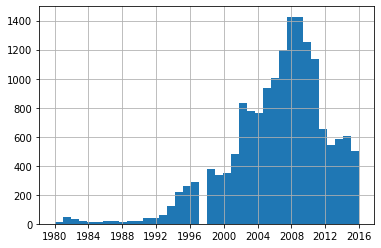

In [109]:
data['year_of_release'].hist(bins=len(data['year_of_release'].unique()))

Посмотрим на распределение игр по годам. Предположительно, отказ от использования 2% датасета не повлечет за собой никаких негативных последствий и упростит работу с данными.

Видим резкое снижение продаж в 2011 году. Период после него будем считать актуальным.

In [110]:
data = data.dropna(subset=['year_of_release', 'name', 'genre'])

<div class="alert-success"> 
<b>Комментарий ревьюера 👍</b> 

Правильно, не стоит бояться удалять данные с пропусками, если их совсем мало

Так и сделаем: удалим из таблицы строки с пропусками в столбцах year_of_release, name, genre.

In [111]:
print(data.isna().sum())

name                  0
platform              0
year_of_release       0
genre                 0
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8461
user_score         6605
rating             6676
dtype: int64


In [112]:
print(len(data))

16444


Как видим, количество строк изменилось несущественно.

In [113]:
print(data['critic_score'].unique())

[76. nan 82. 80. 89. 58. 87. 91. 61. 97. 95. 77. 88. 83. 94. 93. 85. 86.
 98. 96. 90. 84. 73. 74. 78. 92. 71. 72. 68. 62. 49. 67. 81. 66. 56. 79.
 70. 59. 64. 75. 60. 63. 69. 50. 25. 42. 44. 55. 48. 57. 29. 47. 65. 54.
 20. 53. 37. 38. 33. 52. 30. 32. 43. 45. 51. 40. 46. 39. 34. 41. 36. 31.
 27. 35. 26. 19. 28. 23. 24. 21. 17. 13.]


Посмотрим на значения в столбце critic_score, проверим, есть ли в нем некорректные значения или 0. 

In [114]:
print(data['user_score'].unique())

['8' nan '8.3' '8.5' '6.6' '8.4' '8.6' '7.7' '6.3' '7.4' '8.2' '9' '7.9'
 '8.1' '8.7' '7.1' '3.4' '5.3' '4.8' '3.2' '8.9' '6.4' '7.8' '7.5' '2.6'
 '7.2' '9.2' '7' '7.3' '4.3' '7.6' '5.7' '5' '9.1' '6.5' 'tbd' '8.8' '6.9'
 '9.4' '6.8' '6.1' '6.7' '5.4' '4' '4.9' '4.5' '9.3' '6.2' '4.2' '6' '3.7'
 '4.1' '5.8' '5.6' '5.5' '4.4' '4.6' '5.9' '3.9' '3.1' '2.9' '5.2' '3.3'
 '4.7' '5.1' '3.5' '2.5' '1.9' '3' '2.7' '2.2' '2' '9.5' '2.1' '3.6' '2.8'
 '1.8' '3.8' '0' '1.6' '9.6' '2.4' '1.7' '1.1' '0.3' '1.5' '0.7' '1.2'
 '2.3' '0.5' '1.3' '0.2' '0.6' '1.4' '0.9' '1' '9.7']


То же самое для столбца user_score.

In [115]:
print(len(data[data['user_score'] == 0]))

0


In [116]:
for i in ['critic_score', 'user_score']:
    data[i] = data[i].fillna(0)
data['rating'] = data['rating'].fillna('No rating')

Заполним 0 пропуски в значениях столбцов critic_score и user_score, пропуски в столбце rating заполним строкой 'No rating' 

In [117]:
data['user_score'] = data['user_score'].replace('tbd', 0) 

'tbd' означает 'to be determined', поэтому можем заменить его на то же значение, которым заполняли пропуски - рейтинга в таком случае также нет.

In [118]:
data['critic_score'] = data['critic_score'].astype('int')
data['user_score'] = data['user_score'].astype('float')

<div class="alert-success"> 
<b>Комментарий ревьюера 👍 </b>

Верное решение обработать tbd, как nan

Изменим типы данных в столбцах на соответствующие.

In [119]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 16444 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   name             16444 non-null  object        
 1   platform         16444 non-null  object        
 2   year_of_release  16444 non-null  datetime64[ns]
 3   genre            16444 non-null  object        
 4   na_sales         16444 non-null  float64       
 5   eu_sales         16444 non-null  float64       
 6   jp_sales         16444 non-null  float64       
 7   other_sales      16444 non-null  float64       
 8   critic_score     16444 non-null  int64         
 9   user_score       16444 non-null  float64       
 10  rating           16444 non-null  object        
dtypes: datetime64[ns](1), float64(5), int64(1), object(4)
memory usage: 1.5+ MB


Проверим, что типы данных корректкно изменились.

In [120]:
print(data.isna().sum())

name               0
platform           0
year_of_release    0
genre              0
na_sales           0
eu_sales           0
jp_sales           0
other_sales        0
critic_score       0
user_score         0
rating             0
dtype: int64


Пропусков больше нет.

In [121]:
data['overall_sales'] = data['na_sales'] + data['eu_sales'] + data['jp_sales'] + data['other_sales']
data.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,overall_sales
0,Wii Sports,Wii,2006-01-01,Sports,41.36,28.96,3.77,8.45,76,8.0,E,82.54
1,Super Mario Bros.,NES,1985-01-01,Platform,29.08,3.58,6.81,0.77,0,0.0,No rating,40.24
2,Mario Kart Wii,Wii,2008-01-01,Racing,15.68,12.76,3.79,3.29,82,8.3,E,35.52
3,Wii Sports Resort,Wii,2009-01-01,Sports,15.61,10.93,3.28,2.95,80,8.0,E,32.77
4,Pokemon Red/Pokemon Blue,GB,1996-01-01,Role-Playing,11.27,8.89,10.22,1.00,0,0.0,No rating,31.38


<div class="alert-danger"> 
<b>Комментарий ревьюера ❌</b> 

Забыла про other sales

Добавим столбец с суммарными продажами в таблицу, это пригодится далее в ходе исследования.

In [122]:
print(data.duplicated().sum())

0


Проверим данные на наличие дубликатов.

In [123]:
pd.DataFrame(data.groupby('year_of_release')['name'].count().sort_values()).style.background_gradient()


,name
year_of_release,
1980-01-01 00:00:00,9
1984-01-01 00:00:00,14
1985-01-01 00:00:00,14
1988-01-01 00:00:00,15
1990-01-01 00:00:00,16
1987-01-01 00:00:00,16
1989-01-01 00:00:00,17
1983-01-01 00:00:00,17
1986-01-01 00:00:00,21


Посмотрим, сколько игр было выпущено в каждом году. Пик, очевидно, пришелся на 2008. Сейчас их количество имеет тенденцию к уменьшению.

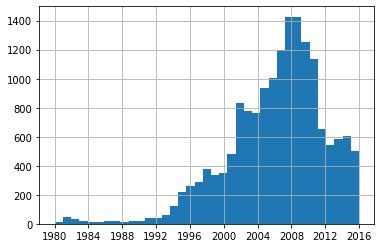

In [124]:
data['year_of_release'].hist(bins=len(data['year_of_release'].unique()))
plt.show();

Более наглядно эту тенденцию к уменьшению иллюстрирует обычная диаграмма. После удаления пропусков в ней больше нет "провала" между 1996 и 2000. Будем считать границу этого провала началом актуального периода.

In [125]:
platform_pivot = data.pivot_table(index='platform', values='overall_sales', aggfunc=['sum', 'mean', 'median'])
platform_pivot.columns = ['sum', 'mean', 'median']
print(platform_pivot.sort_values(by='sum', ascending=False))

              sum      mean  median
platform                           
PS2       1233.56  0.579953   0.230
X360       961.24  0.780227   0.280
PS3        931.34  0.713124   0.280
Wii        891.18  0.692986   0.190
DS         802.78  0.378491   0.110
PS         727.58  0.611412   0.260
PS4        314.14  0.801378   0.200
GBA        312.88  0.385795   0.160
PSP        289.53  0.242691   0.090
3DS        257.81  0.503535   0.120
PC         255.76  0.267252   0.050
GB         254.43  2.622990   1.180
XB         251.57  0.313288   0.150
NES        251.05  2.561735   1.375
N64        218.01  0.689905   0.270
SNES       200.04  0.836987   0.320
GC         196.73  0.362970   0.150
XOne       159.32  0.645020   0.220
2600        86.48  0.745517   0.480
WiiU        82.19  0.559116   0.220
PSV         53.81  0.125431   0.050
SAT         33.59  0.194162   0.120
GEN         28.35  1.050000   0.150
DC          15.95  0.306731   0.135
SCD          1.86  0.310000   0.065
NG           1.44  0.120000 

Посмотрим на показатели продаж для различных платформ. Видим, что платформы имеющие наибольшие суммарные продажи необязательно имеют наилучшие показатели медианных и средних значений.

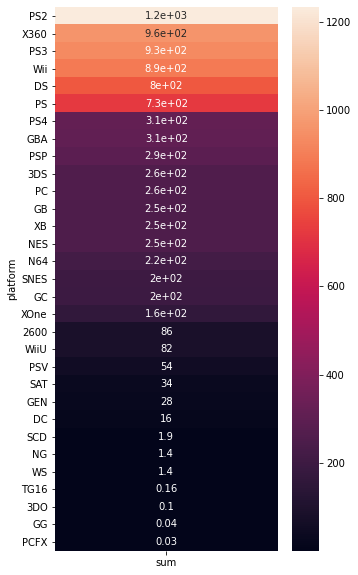

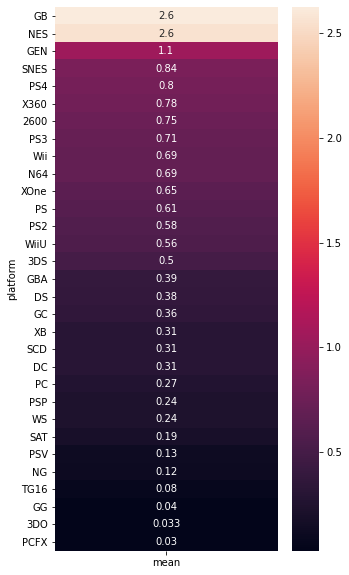

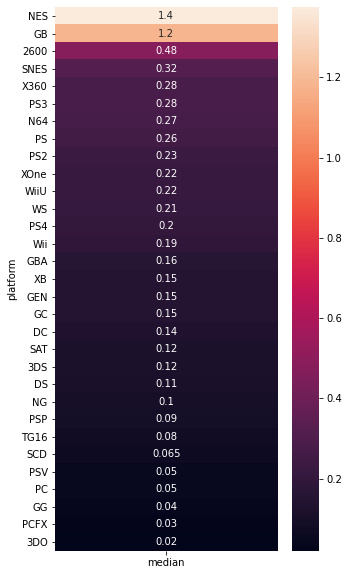

In [126]:
for i in list(platform_pivot.columns):
    plt.figure(figsize=(5,10))
    sns.heatmap(platform_pivot[[i]].sort_values(by=i, ascending=False), annot=True)
    plt.show();

Из таблиц выше видим, что наилучшие показатели сумммарных продаж характерны для платформ PS2, X360, Wii, PS3, DS, PS, соответственно.

Совсем другие платформы имеют наилучшие показатели продаж, если смотреть по среднему. Это GB и NES. Это может указывать на наличие выбросов в продажах данных платформ. Т. е. при не очень больших продажах основной массы игр, были и очень успешные продукты.

Наилучшие медианные показатели также имеют NES и GB. Это можно объяснить тем, что это наиболее "эффективные" платформы. На них мало игр, но имеющиеся являются успешными.

<div class="alert-success"> 
<b>Комментарий ревьюера 👍 </b>

Да, согласен

In [127]:
platforms_by_years = data[pd.DatetimeIndex(data['year_of_release']).year >= 1998].pivot_table(index=
                                    'year_of_release', columns='platform', values='overall_sales', 
                                      aggfunc=['count']).fillna(-100)

platforms_by_years.columns = [i for i in platforms_by_years['count'].columns]
print(platforms_by_years)

                   3DS     DC     DS     GB    GBA     GC    N64     PC  \
year_of_release                                                           
1998-01-01      -100.0    7.0 -100.0    8.0 -100.0 -100.0   77.0    8.0   
1999-01-01      -100.0   14.0 -100.0   11.0 -100.0 -100.0  102.0    7.0   
2000-01-01      -100.0   20.0 -100.0   17.0    1.0 -100.0   60.0    7.0   
2001-01-01      -100.0    8.0 -100.0   10.0  107.0   22.0    9.0   15.0   
2002-01-01      -100.0    1.0 -100.0 -100.0  198.0  152.0    1.0   19.0   
2003-01-01      -100.0 -100.0 -100.0 -100.0  150.0  144.0 -100.0   33.0   
2004-01-01      -100.0 -100.0   23.0 -100.0  175.0   83.0 -100.0   30.0   
2005-01-01      -100.0 -100.0  118.0 -100.0  135.0   97.0 -100.0   37.0   
2006-01-01      -100.0 -100.0  201.0 -100.0   39.0   40.0 -100.0   52.0   
2007-01-01      -100.0    1.0  376.0 -100.0    6.0    4.0 -100.0   62.0   
2008-01-01      -100.0    1.0  492.0 -100.0 -100.0 -100.0 -100.0   76.0   
2009-01-01      -100.0 -1

Посмотрим на наличие и количество игр каждой из платформ в каждом году из актуального периода.

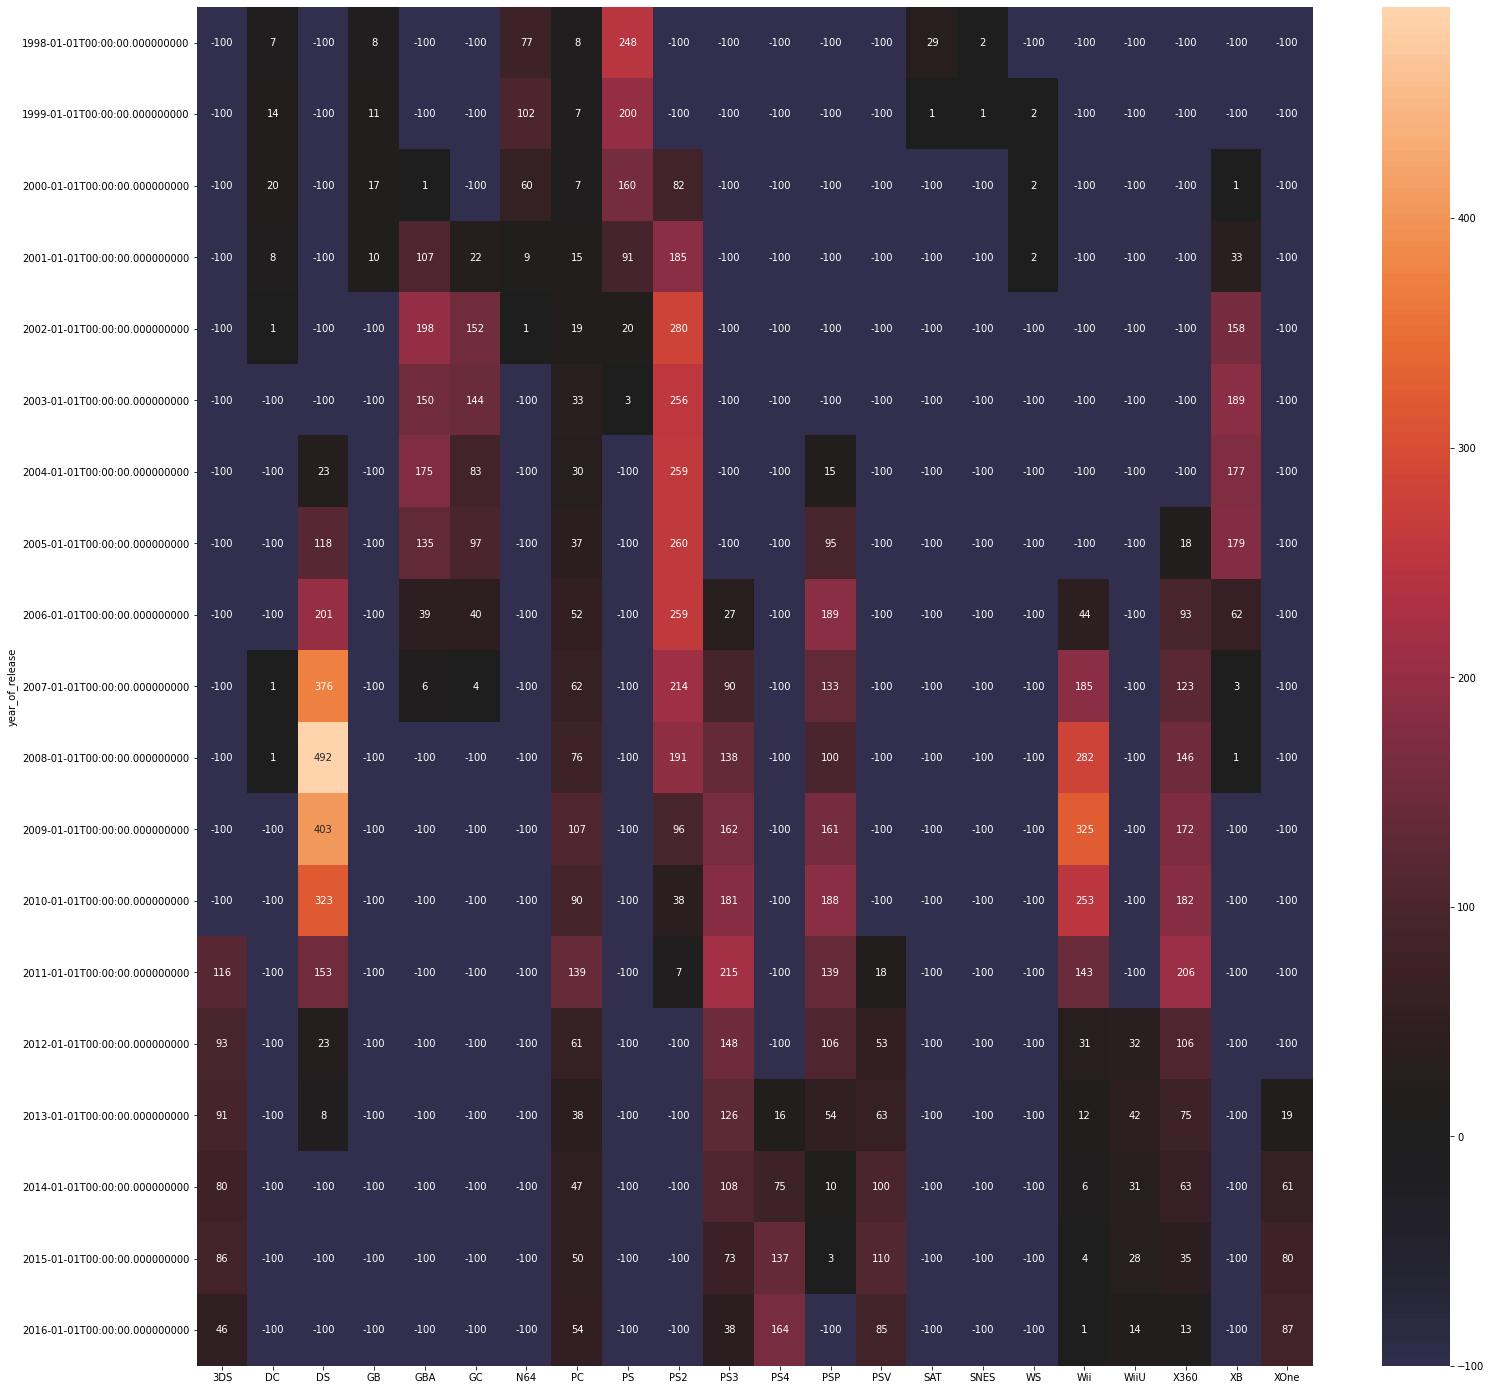

In [128]:
plt.figure(figsize=(25,25))
sns.heatmap(platforms_by_years, annot=True, fmt='.0f', vmin=-100, center= 0)
plt.show();

Та же таблица за актуальный период:

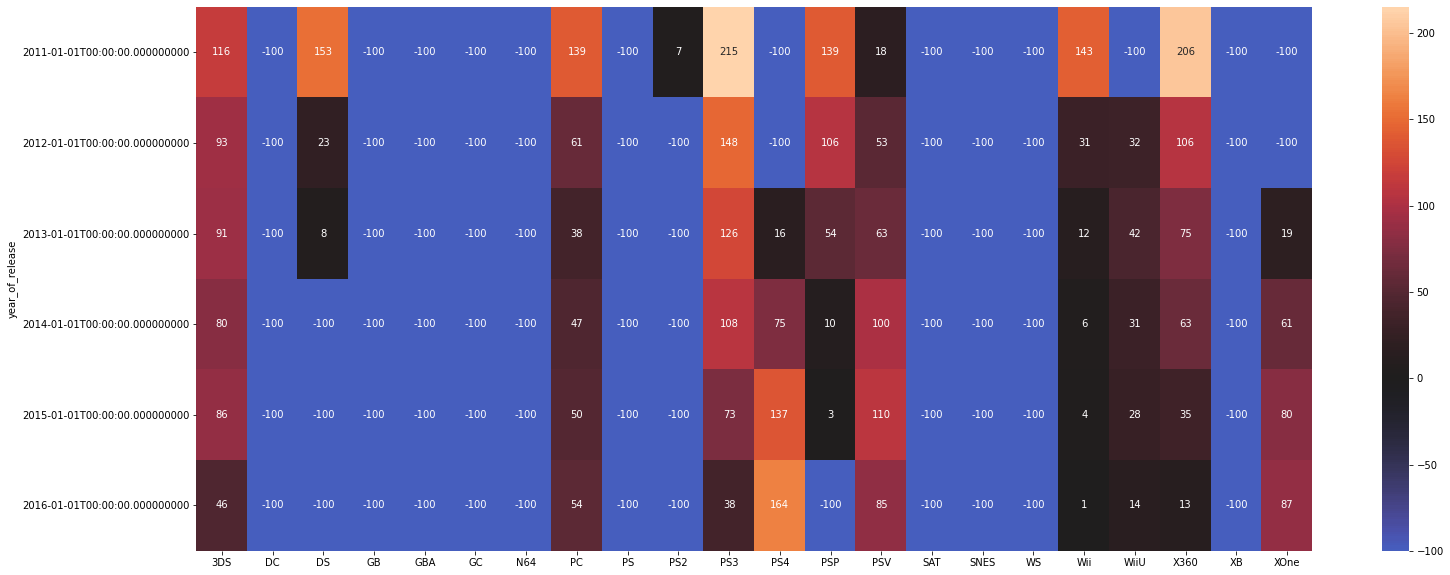

In [129]:
plt.figure(figsize=(25,10))
sns.heatmap(platforms_by_years[pd.DatetimeIndex(platforms_by_years.index).year >= 2011], annot=True, fmt='.0f', vmin=-100, center= 0)
plt.show();

<div class="alert-success"> 
<b>Комментарий ревьюера 👍 </b>

Хороший heatmap

Данная таблица позволит сделать эту информацию более наглядной. Видно, что в основном количество игр на платформах уменьшается. Наиболее активными остаются 3DS, PC, PS3, PS4, PSV, WiiU, X360, XOne.

In [130]:
list_of_years = []
for i in ['DS', 'GBA', 'GC', 'PS2', 'PSP', 'WS', 'XB']:
    cnt = 0
    for j in platforms_by_years.index:
        if platforms_by_years.loc[j, i] > 0:
            cnt += 1
    list_of_years.append(cnt)
    
print(mean(list_of_years), median(list_of_years))

8.714285714285714 9


Рассчитаем характерный срок существования платформ как среднее или медиану (их значения получились достаточно близкими) времени активности платформ, которые появились и перестали активно использоваться в течение актуального периода. Это DS, GBA, GC, PS2, PSP, WS, XB.

Из этого следует, что жизненный цикл платформы в среднем равен 9 годам.

In [131]:
platforms_by_years_sum_sales = data[pd.DatetimeIndex(data['year_of_release']).year >= 1998].pivot_table(index=
                                    'year_of_release', columns='platform', values='overall_sales', 
                                      aggfunc=['sum']).fillna(-100)

platforms_by_years_sum_sales.columns = [i for i in platforms_by_years_sum_sales['sum'].columns]
print(platforms_by_years_sum_sales)

                    3DS      DC      DS      GB     GBA      GC     N64  \
year_of_release                                                           
1998-01-01      -100.00    3.38 -100.00   26.90 -100.00 -100.00   49.24   
1999-01-01      -100.00    5.16 -100.00   38.00 -100.00 -100.00   57.87   
2000-01-01      -100.00    5.99 -100.00   19.76    0.07 -100.00   33.97   
2001-01-01      -100.00    1.07 -100.00    9.24   61.53   26.34    3.25   
2002-01-01      -100.00    0.29 -100.00 -100.00   74.16   51.81    0.08   
2003-01-01      -100.00 -100.00 -100.00 -100.00   56.67   50.61 -100.00   
2004-01-01      -100.00 -100.00   17.27 -100.00   77.91   28.82 -100.00   
2005-01-01      -100.00 -100.00  130.14 -100.00   33.86   27.62 -100.00   
2006-01-01      -100.00 -100.00  119.81 -100.00    5.28   11.26 -100.00   
2007-01-01      -100.00    0.02  146.94 -100.00    3.40    0.27 -100.00   
2008-01-01      -100.00    0.04  145.31 -100.00 -100.00 -100.00 -100.00   
2009-01-01      -100.00 -

<div class="alert-danger"> 
<b>Комментарий ревьюера ❌</b> 

Какой в итоге срок / цикл?

Посмотрим на суммарные продажи.

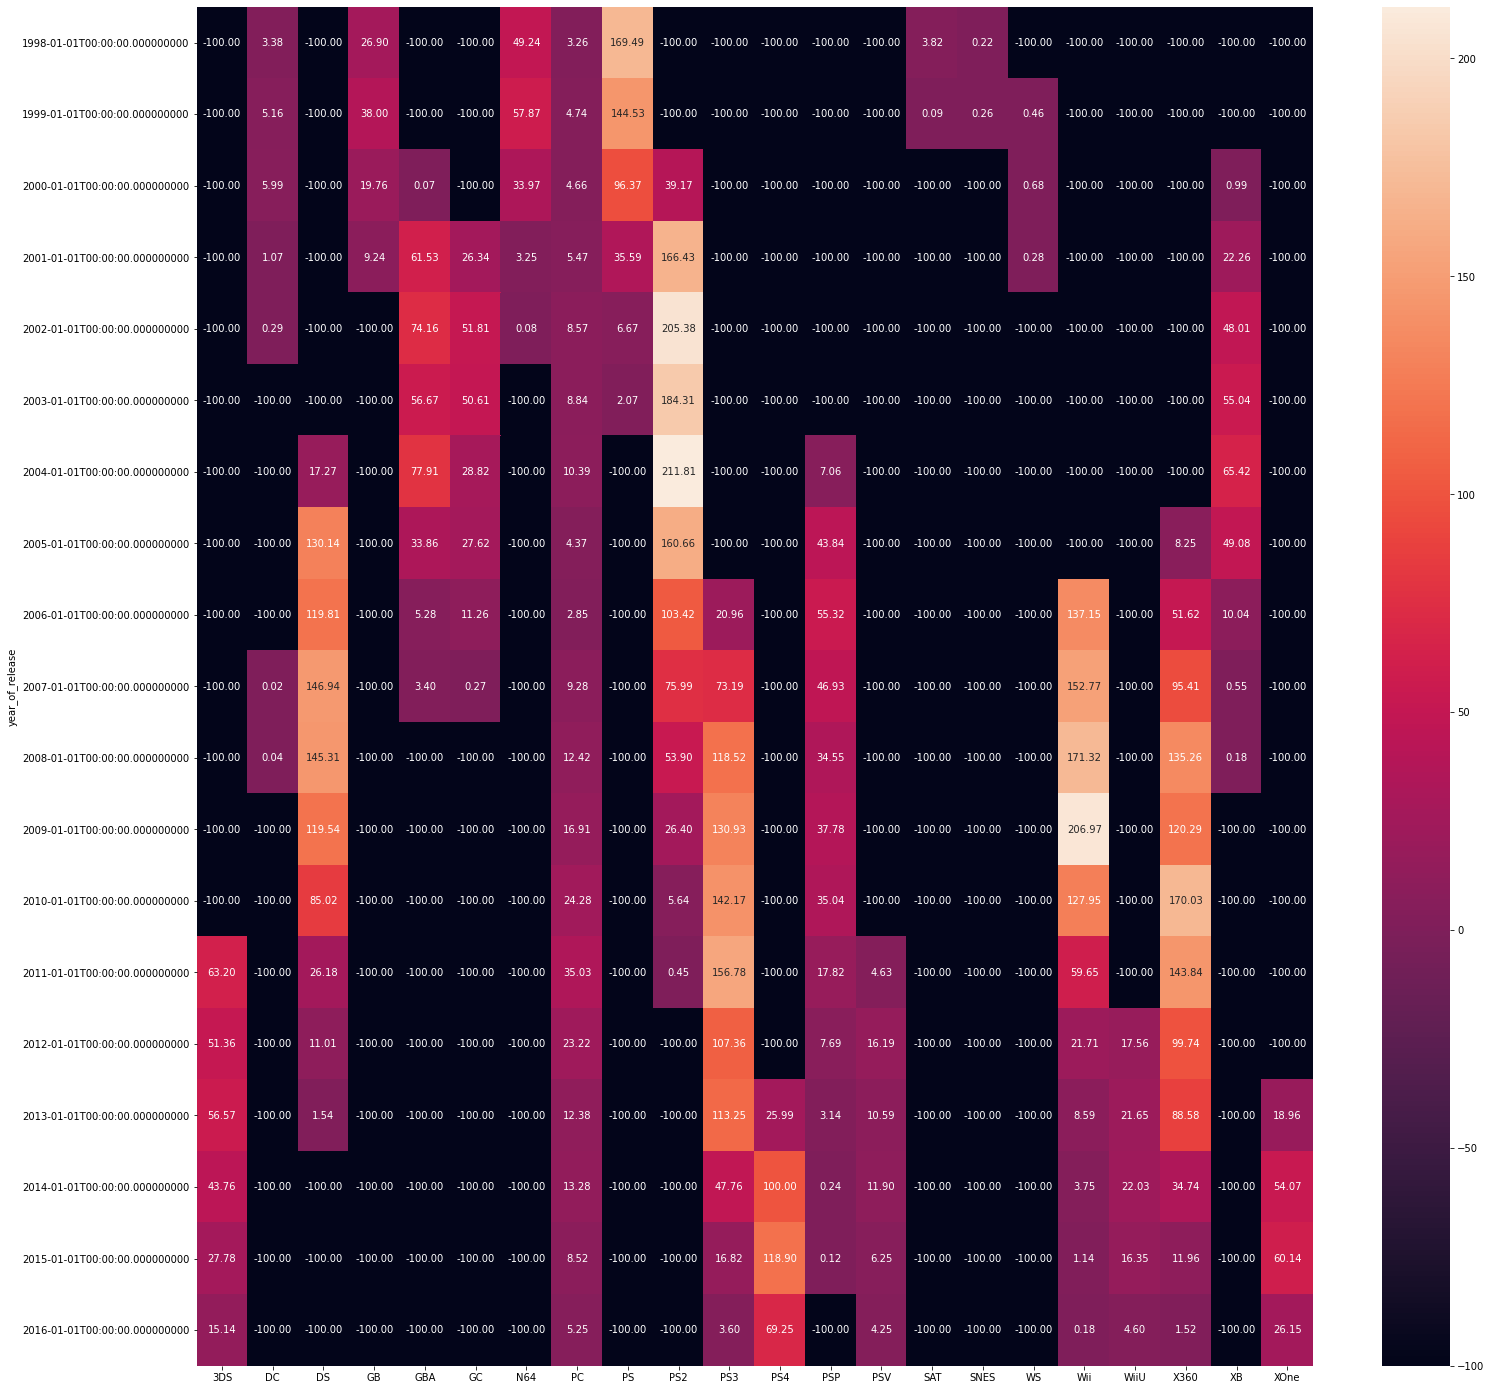

In [132]:
plt.figure(figsize=(25,25))
sns.heatmap(platforms_by_years_sum_sales, annot=True, fmt='.2f')
plt.show();

Та же таблица за актуальный период:

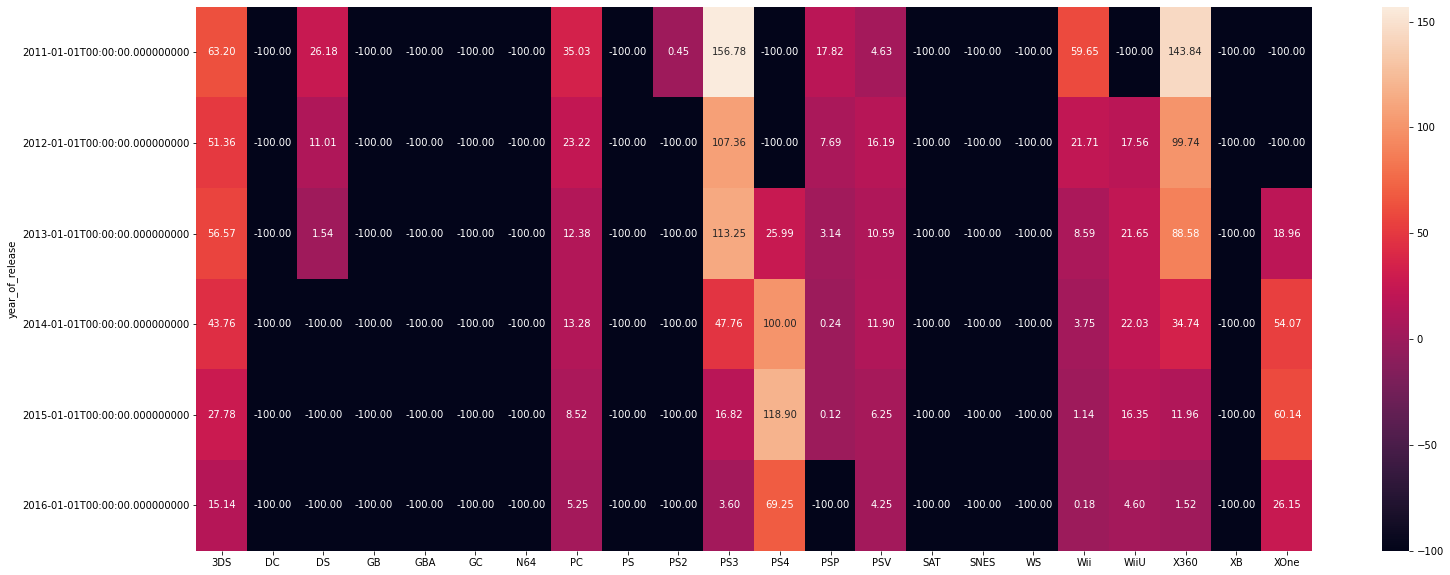

In [133]:
plt.figure(figsize=(25,10))
sns.heatmap(platforms_by_years_sum_sales[pd.DatetimeIndex(platforms_by_years_sum_sales.index).year >= 2011], annot=True, fmt='.2f')
plt.show();

<div class="alert-danger"> 
<b>Комментарий ревьюера ❌</b> 

Не выполнен пункт: "Возьмите данные за соответствующий актуальный период. Актуальный период определите самостоятельно в результате исследования предыдущих вопросов. Основной фактор — эти данные помогут построить прогноз на 2017 год."]

Суммарные продажи уменьшаются у всех действующих платформ.

Ввиду общего снижения успешности игровых платформ и в контексте решения конкретной задачи наиболее перспективные следует определять из медианы продаж.

In [134]:
platforms_by_years_median_sales = data[pd.DatetimeIndex(data['year_of_release']).year >= 1998].pivot_table(index=
                                    'year_of_release', columns='platform', values='overall_sales', 
                                      aggfunc=['median']).fillna(-100)

platforms_by_years_median_sales.columns = [i for i in platforms_by_years_median_sales['median'].columns]
print(platforms_by_years_median_sales)

                     3DS       DC       DS       GB      GBA       GC  \
year_of_release                                                         
1998-01-01      -100.000    0.140 -100.000    2.070 -100.000 -100.000   
1999-01-01      -100.000    0.275 -100.000    0.770 -100.000 -100.000   
2000-01-01      -100.000    0.120 -100.000    0.810    0.070 -100.000   
2001-01-01      -100.000    0.120 -100.000    0.725    0.190    0.510   
2002-01-01      -100.000    0.290 -100.000 -100.000    0.140    0.130   
2003-01-01      -100.000 -100.000 -100.000 -100.000    0.170    0.105   
2004-01-01      -100.000 -100.000    0.170 -100.000    0.220    0.220   
2005-01-01      -100.000 -100.000    0.130 -100.000    0.140    0.150   
2006-01-01      -100.000 -100.000    0.110 -100.000    0.040    0.155   
2007-01-01      -100.000    0.020    0.115 -100.000    0.205    0.060   
2008-01-01      -100.000    0.040    0.100 -100.000 -100.000 -100.000   
2009-01-01      -100.000 -100.000    0.110 -100.000

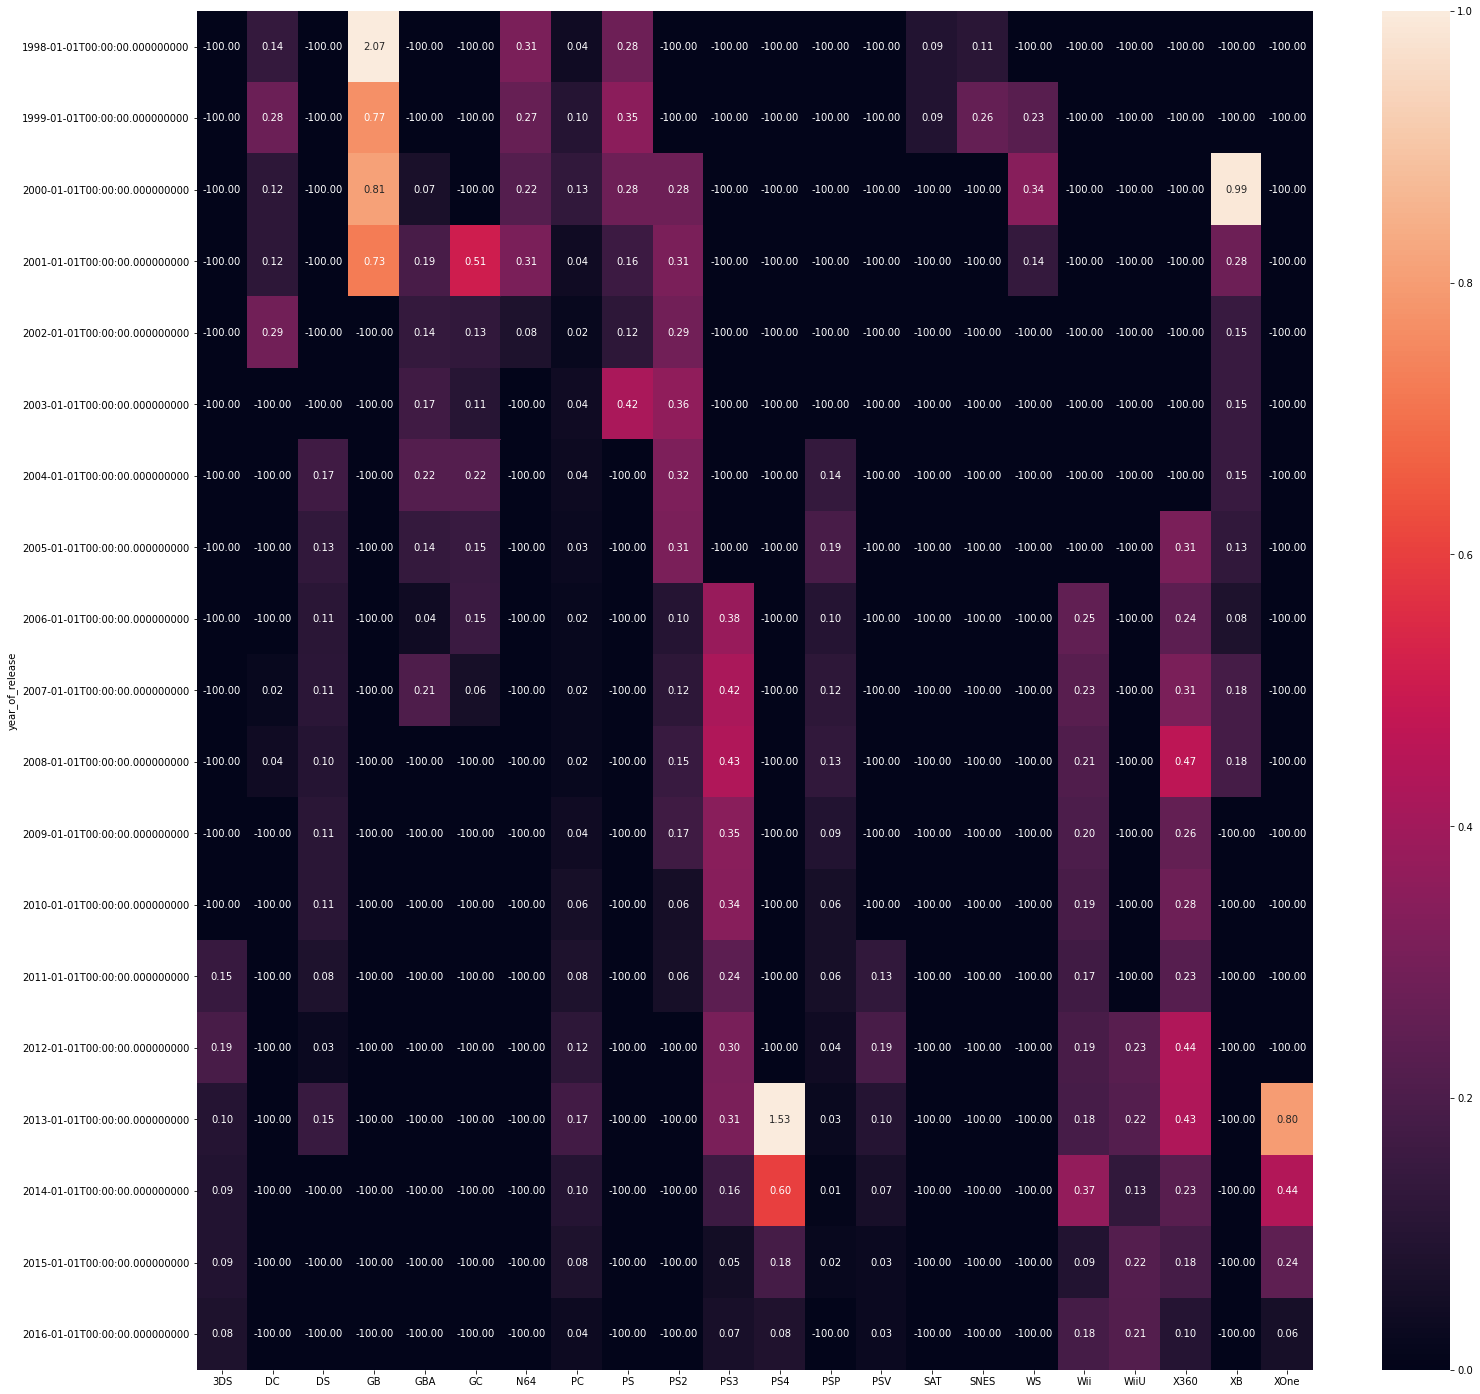

In [135]:
plt.figure(figsize=(25,25))
sns.heatmap(platforms_by_years_median_sales, annot=True, fmt='.2f', vmin=0, vmax=1)
plt.show();

Та же таблица за актуальный период:

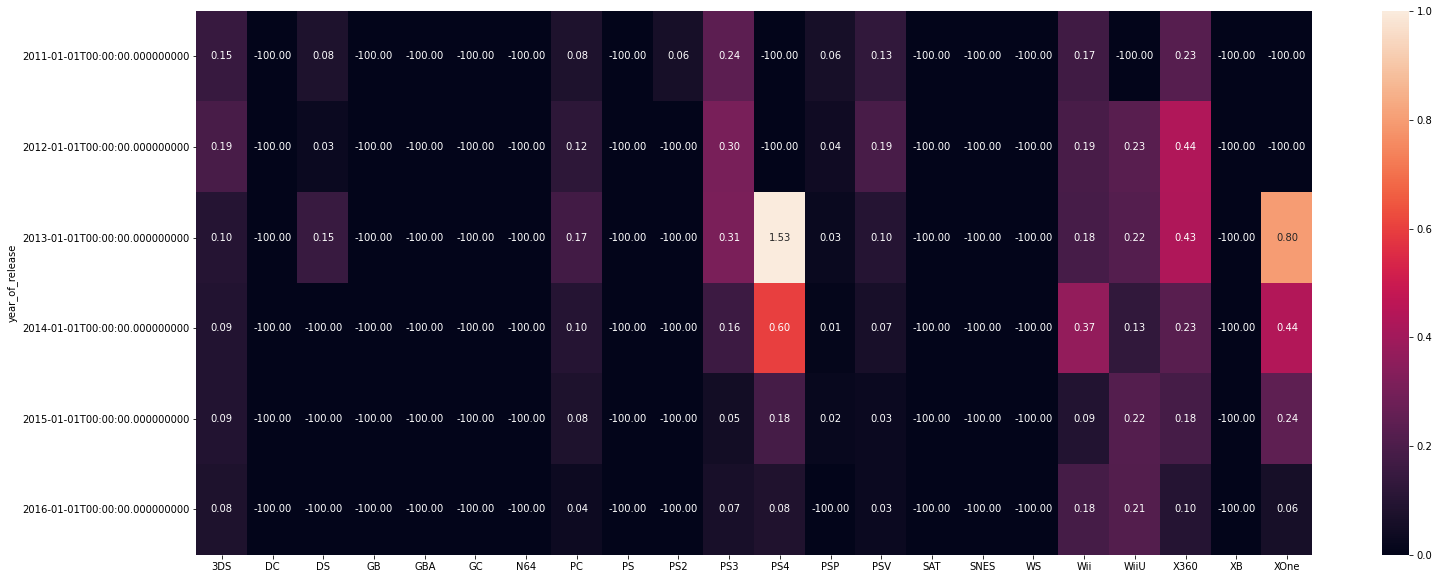

In [136]:
plt.figure(figsize=(25,10))
sns.heatmap(platforms_by_years_median_sales[pd.DatetimeIndex(platforms_by_years_median_sales.index).year >= 2011], annot=True, fmt='.2f', vmin=0, vmax=1)
plt.show();

Итак, наиболее активными в общем являются платформы 3DS, PC, PS3, PS4, PSV, Wii, WiiU, X360 и XOne.

Следует отметить, что за последний год из них объемы продаж выросли только у PS3 и Wii. Не изменились объемы продаж у PSV и WiiU. Эти платформы следует считать наиболее перспективными. У остальных платформ объемы продаж упали. В качестве платформ, которые также было бы полезно учитывать, необходимо назвать 3DS и PC, так как объемы их продаж относительно стабильны на протяжении нескольких лет.

3DS


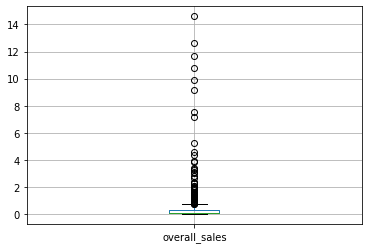

DC


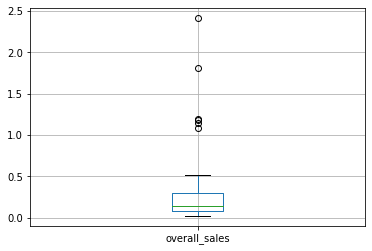

DS


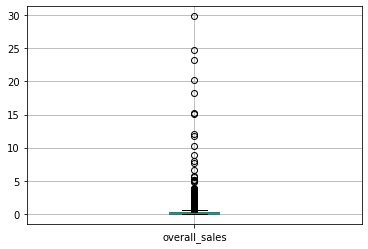

GB


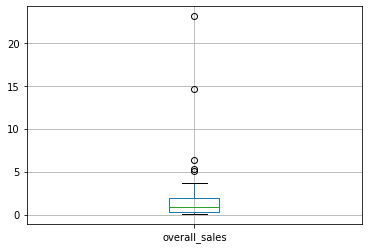

GBA


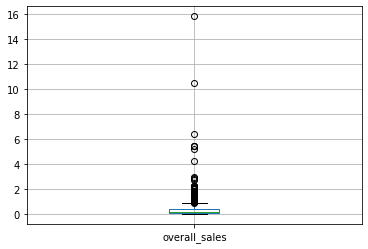

GC


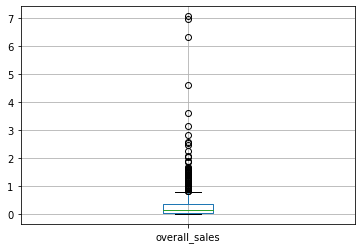

N64


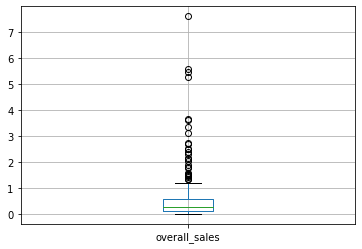

PC


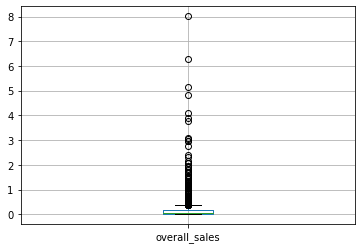

PS


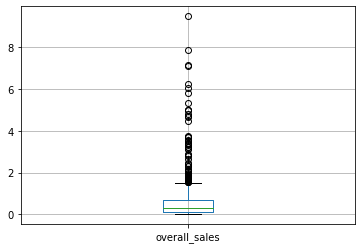

PS2


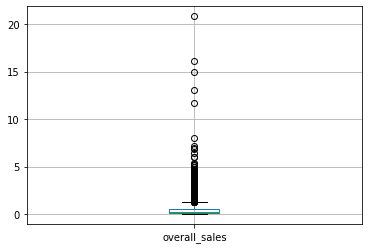

PS3


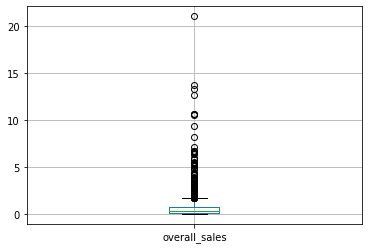

PS4


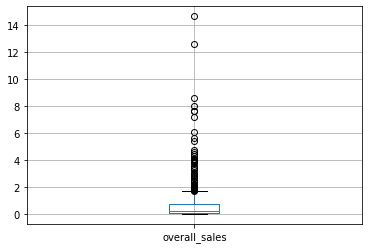

PSP


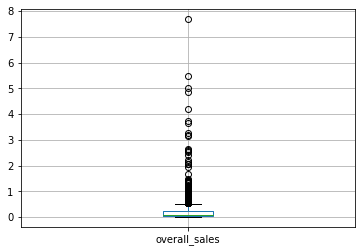

PSV


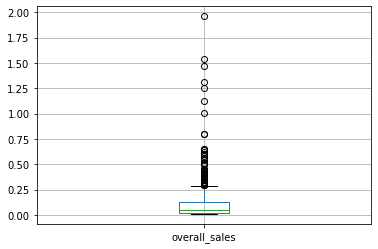

SAT


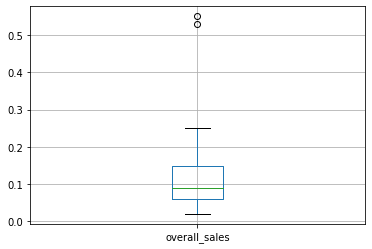

SNES


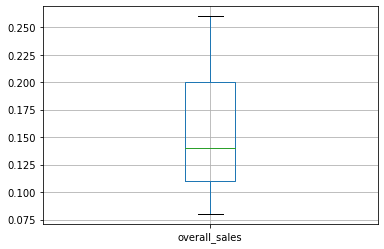

WS


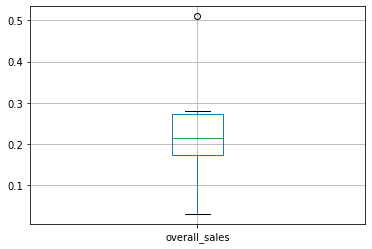

Wii


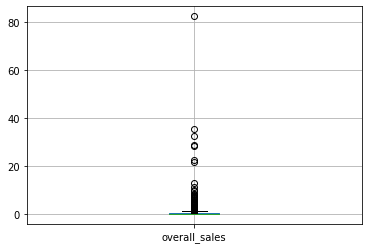

WiiU


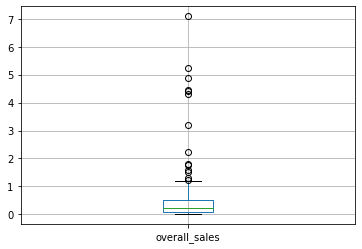

X360


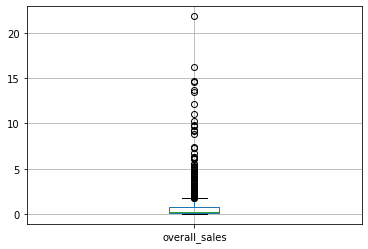

XB


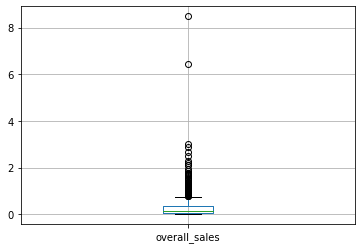

XOne


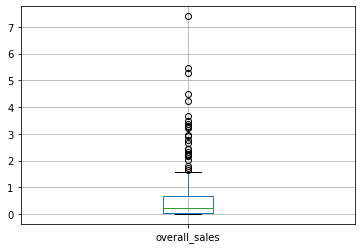

In [137]:
for i in platforms_by_years.columns:
    print(i)
    data[(data['platform'] == i) & (pd.DatetimeIndex(data['year_of_release']).year >= 1998)].boxplot(column='overall_sales')
    plt.show();

Построим диаграммы разброса значений суммарных продаж для всех платформ.

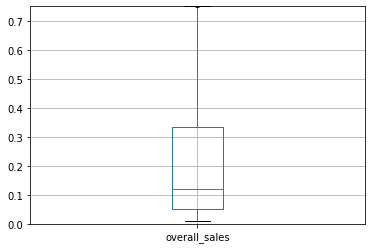

In [138]:
plt.ylim(0, 0.75) 
data[(data['platform'] == '3DS') & (pd.DatetimeIndex(data['year_of_release']).year
                                    >= 2011)].boxplot(column='overall_sales')
plt.show()

Теперь перейдем к наиболее активным в последнее время.

3DS - одна из наиболее стабильных платформ. Ее медиана расположена чуть выше 0.1, третий квартал смещен вверх (чуть больше 0.3)

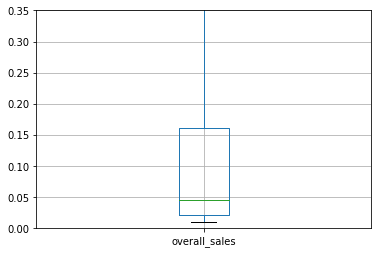

In [139]:
plt.ylim(0, 0.35) 
data[(data['platform'] == 'PC') & (pd.DatetimeIndex(data['year_of_release']).year >= 1998)].boxplot(column='overall_sales')
plt.show()

Платформа PC также стабильна. Но в основном значения ее продаж значительно (где-то в 2 раза) меньше, чем у предыдущей платформы: медиана - чуть меньше 0.05, третий квартал - чуть меньше 0.15. Менее выгодно инвестировать сюда. 

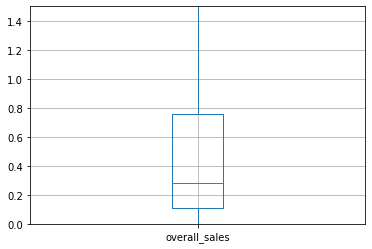

In [140]:
plt.ylim(0, 1.5) 
data[(data['platform'] == 'PS3') & (pd.DatetimeIndex(data['year_of_release']).year >= 2006)].boxplot(column='overall_sales')
plt.show()

Платформа PS3 одна из самых перспективных, ведь за последний год, несмотря на общую тенденцию, ее продажи немного увеличились. Об этом говорит и ее диаграмма размаха: медиана значительно больше, чем у двух предыдущих платформ (примерно 0.25), третий квартал - почти 0.7.

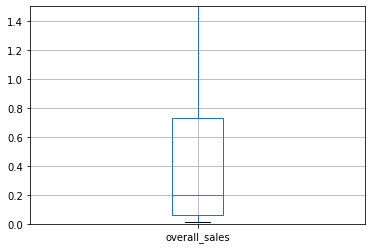

In [141]:
plt.ylim(0, 1.5) 
data[(data['platform'] == 'PS4') & (pd.DatetimeIndex(data['year_of_release']).year >= 2013)].boxplot(column='overall_sales')
plt.show()

Продажи PS4 с каждым годом стремительно снижаются, но и стабильностью эта платформа похвастаться не может. ЕЕ медианное значение однако относительно невелико, около 0.2, третий квартал также существенно смещен вверх.

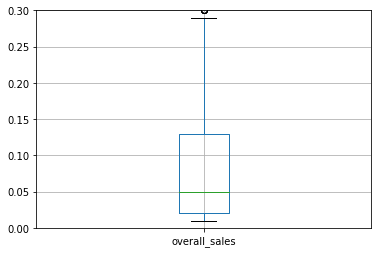

In [142]:
plt.ylim(0, 0.3) 
data[(data['platform'] == 'PSV') & (pd.DatetimeIndex(data['year_of_release']).year >= 2011)].boxplot(column='overall_sales')
plt.show()

Объемы продаж у PSV не изменились за последний год, но медианное значение совсем невелико - 0.05.

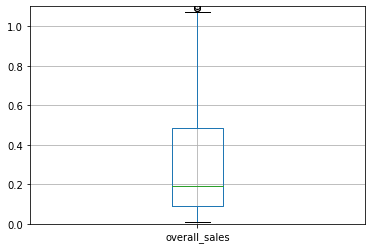

In [143]:
plt.ylim(0, 1.1) 
data[(data['platform'] == 'Wii') & (pd.DatetimeIndex(data['year_of_release']).year >= 2006)].boxplot(column='overall_sales')
plt.show()

Наиболее значительный прирост в продажах наблюдался у Wii. Ее медианное значение очти достигает 0.2, но третий квартал смещен вверх не так сильно как у остальных платформ с похожим медианным значением.

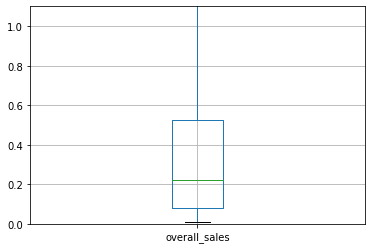

In [144]:
plt.ylim(0, 1.1) 
data[(data['platform'] == 'WiiU') & (pd.DatetimeIndex(data['year_of_release']).year >= 2012)].boxplot(column='overall_sales')
plt.show()

WiiU показывает тоже очень стабильные результаты на протяжении нескольких лет. При этом ее медианное значение довольно высокое, а третий квартал смещен вверх относительно несильно.

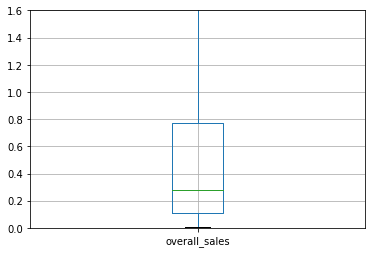

In [145]:
plt.ylim(0, 1.6) 
data[(data['platform'] == 'X360') & (pd.DatetimeIndex(data['year_of_release']).year >= 2005)].boxplot(column='overall_sales')
plt.show()

Медианное значение продаж X360 падает уже несколько лет, но в общем ее медианное значение остается на высоте.

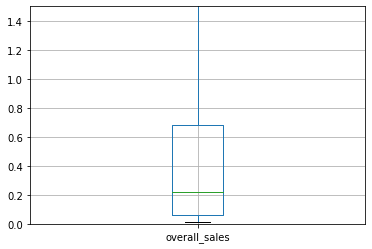

In [146]:
plt.ylim(0, 1.5) 
data[(data['platform'] == 'XOne') & (pd.DatetimeIndex(data['year_of_release']).year >= 2013)].boxplot(column='overall_sales')
plt.show()

XOne существует недолго и ее медианные продажи падают. Но в целом эта платформа может похвастаться большими масштабами: относительно высоким значением медианы и сильно смещенным вверх третьим кварталом на диаграмме размаха.

Резюмируя:

Учитывая динамику изменения медианных объемов продаж за последние годы и общее медианное значение на диаграмме размаха, характеризующее масштабность платформ, наиболее выгодно инвестировать будет в PS3, Wii, WiiU.

<div class="alert-success"> 
<b>Комментарий ревьюера 👍 </b>

Отличный анализ платформ!

Перейдем к выяснению взаимосвязи между продажами и оценками игр. Сделаем это на примере платформы PS3, ведь динамика е е продаж за последние годы наиболее впечатляющая.

In [147]:
data[data['platform'] == 'PS3']['critic_score'].corr(data[data['platform'] == 'PS3']['overall_sales'])

0.35514556594230773

Найдем корреляцию между оценками критиков и объемами продаж платформы PS3. Она положительная, однако несильная

In [148]:
data[data['platform'] == 'PS3']['user_score'].corr(data[data['platform'] == 'PS3']['overall_sales'])

0.2745827060165664

Найдем корреляцию между оценками пользователей и объемами продаж платформы PS3. Она положительная, но еще менее сильная, чем предыдущий показатель.

In [149]:
data['critic_score_category'] = np.NaN
data.loc[data['critic_score'] == 0, 'critic_score_category'] = 'F'
data.loc[(data['critic_score'] < 20) & (data['critic_score'] > 0), 'critic_score_category'] = 'E'
data.loc[(data['critic_score'] < 40) & (data['critic_score'] >= 20), 'critic_score_category'] = 'D'
data.loc[(data['critic_score'] < 60) & (data['critic_score'] >= 40), 'critic_score_category'] = 'C'
data.loc[(data['critic_score'] < 80) & (data['critic_score'] >= 60), 'critic_score_category'] = 'B'
data.loc[data['critic_score'] >= 80, 'critic_score_category'] = 'A'

Категоризуем данные об оценках критиков.

In [150]:
data['user_score_category'] = np.NaN
data.loc[data['user_score'] == 0.0, 'user_score_category'] = 'F'
data.loc[(data['user_score'] < 2.0) & (data['user_score'] > 0.0), 'user_score_category'] = 'E'
data.loc[(data['user_score'] < 4.0) & (data['user_score'] >= 2.0), 'user_score_category'] = 'D'
data.loc[(data['user_score'] < 6.0) & (data['user_score'] >= 4.0), 'user_score_category'] = 'C'
data.loc[(data['user_score'] < 8.0) & (data['user_score'] >= 6.0), 'user_score_category'] = 'B'
data.loc[data['user_score'] >= 8.0, 'user_score_category'] = 'A'

<div class="alert-success"> 
<b>Комментарий ревьюера 👍 </b>

Хорошая идея, но лучше было оставить численные значения

Категоризуем данные об оценках пользователей.

In [151]:
def pivot_and_graphics(array, category):
    array_pivot = array.pivot_table(index=category, values='overall_sales', aggfunc=['count', 'mean', 'median', 'sum'])
    array_pivot.columns = ['count', 'mean', 'median', 'sum']
    print(array_pivot)
    for i in list(array_pivot.columns):
        plt.figure(figsize=(1,2))
        sns.heatmap(array_pivot[[i]], annot=True)
        plt.show();  


Напишем функцию, которая поможет визуализировать зависимость между категорией и продажами.

                       count      mean  median     sum
critic_score_category                                 
A                        248  2.064879    1.22  512.09
B                        382  0.596440    0.40  227.84
C                        155  0.303613    0.21   47.06
D                         17  0.163529    0.14    2.78
E                          2  0.070000    0.07    0.14
F                        502  0.281733    0.10  141.43


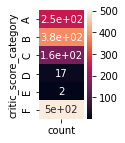

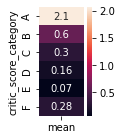

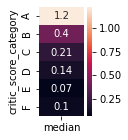

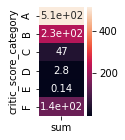

In [152]:
PS3_data = data[data['platform'] == 'PS3']
pivot_and_graphics(PS3_data, 'critic_score_category')

Создадим срез данных для платформы PS3.

Увидим, что больше всего игр на данной платформе имеют категорию F, т. е. не имеют рейтинга, так как выше мы заполнили нулем пропуски. Вторая по количеству игр - категория B. Однако сумма продаж в этой категории сильно уступает категории A. Обратимся к среднему и медиане продаж. Для категории А они в несколько раз больше. Выходит, рейтинги критиков сильно влияют на продажи PS3? Этого нельзя однозначно утверждать, ведь высокий рейтинг критиков - следствие из хорошего качества продукта, а спрос на качественную продукцию всегда, как правило, выше.

                       count      mean  median      sum
critic_score_category                                  
A                       1979  1.498848    0.68  2966.22
B                       4137  0.497999    0.22  2060.22
C                       1589  0.286199    0.15   454.77
D                        270  0.191407    0.10    51.68
E                          8  0.095000    0.08     0.76
F                       8461  0.387746    0.12  3280.72


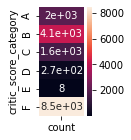

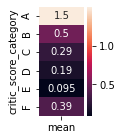

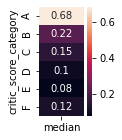

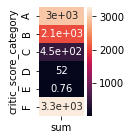

In [153]:
pivot_and_graphics(data, 'critic_score_category')

Соотнесем с результатами по всем платформам. Здесь соотношение количества игр А / В еще меньше, что указывает на то, что PS3 в целом имеет хорошие показатели. Однако продажи категории А не так сильно превышают продажи категории В как в конкретном случае PS3.

                     count      mean  median     sum
user_score_category                                 
A                      153  1.523333   0.930  233.07
B                      508  0.890945   0.510  452.60
C                      147  0.699864   0.300  102.88
D                       45  0.872667   0.230   39.27
E                        8  0.168750   0.135    1.35
F                      445  0.229596   0.090  102.17


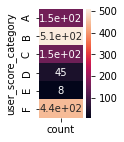

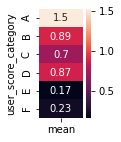

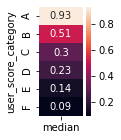

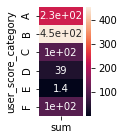

In [154]:
pivot_and_graphics(PS3_data, 'user_score_category')

Посмотрим на оценки пользователей для PS3. Здесь категория F уже не занимает лидирующую позицию. Самой большой по количеству игр является категория В. Интересно, что здесь и суммарные продажи для этой категории больше. Ведь соотношение количества игр А / Б еще меньше, чем в предыдущих случаях. Но среднее и медиана не дадут обмануть: игры категории А продаются наиболее эффективно.

                     count      mean  median      sum
user_score_category                                  
A                     2544  0.966576    0.36  2458.97
B                     3550  0.676682    0.27  2402.22
C                     1030  0.517223    0.23   532.74
D                      291  0.491031    0.14   142.89
E                       47  0.185745    0.10     8.73
F                     8982  0.363930    0.11  3268.82


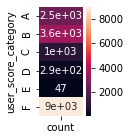

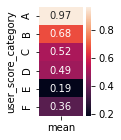

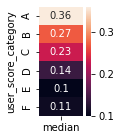

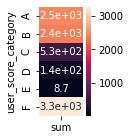

In [155]:
pivot_and_graphics(data, 'user_score_category')

И снова количество игр в категории F существенно преобладает. Значит, пользователи охотно дают оценку играм на платформе PS3. Интересно, что суммарные продажи, среднее и медиана категории А лишь немного превышают эти значения для категории В.

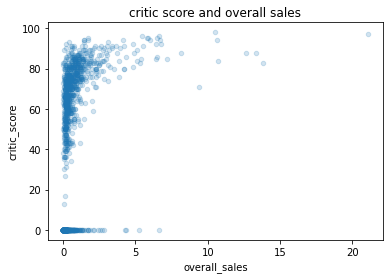

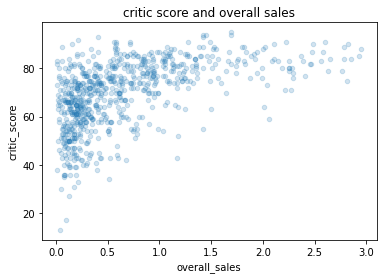

In [156]:
PS3_data.plot(kind='scatter', x='overall_sales', y='critic_score', alpha=0.2, title='critic score and overall sales')
plt.show();
PS3_data[(PS3_data['critic_score'] != 0) & (PS3_data['overall_sales'] <= 3)].plot(kind='scatter', x='overall_sales', y='critic_score', alpha=0.2, title='critic score and overall sales')
plt.show();

<div class="alert-success"> 
<b>Комментарий ревьюера 👍 </b>

В идеале графики можно еще подписать

Посмотрим диаграммы рассеяния, визуализирующие взаимосвязь между оценками критиков и продажами для платформы PS3. В целом, чем выше оценка критика, тем больше вероятность для игры быть успешой. Однако, видим массу точек, выбивающихся из общей тенденции: при высоких оценках критиков, они не продаются более эффективно, чем те, которые были оценены хуже.
Важно не забывать, что множество точек около нуля, среди которых есть и те, которые продаются весьма эффективно, - это игры, не получившие рейтинга вовсе.

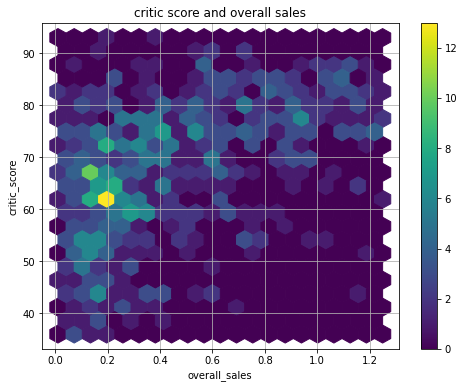

In [157]:
PS3_data[(PS3_data['critic_score'] > 35) & (PS3_data['overall_sales'] <= 1.25)].plot(kind='hexbin', 
                        x='overall_sales', y='critic_score', gridsize=20, figsize=(8, 6),
                          sharex=False, grid=True, reduce_C_function=np.mean, cmap="viridis",
                       title='critic score and overall sales')
plt.show()

Эта диаграмма более удачно визуализирует распределение игр внутри множества точек на диаграмме рассеяния. Видно, что больше всего игр сосредоточено около 1.8 по оси Х, и 65 по оси У.

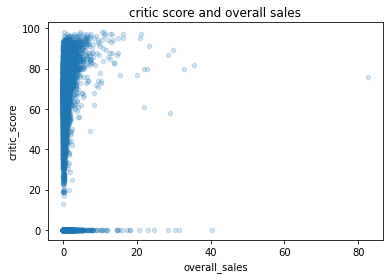

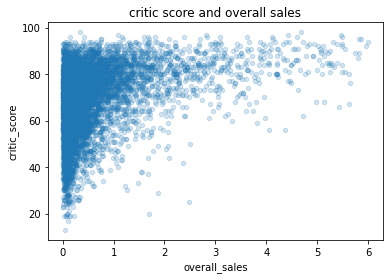

In [158]:
data.plot(kind='scatter', x='overall_sales', y='critic_score', alpha=0.2, title='critic score and overall sales')
plt.show();
data[(data['critic_score'] != 0) & (data['overall_sales'] <= 6)].plot(kind='scatter', x='overall_sales', y='critic_score', alpha=0.2, title='critic score and overall sales')
plt.show();

Из этих диагармм видно, что для всех остальных платформ шанс игры на эффективную продажу увеличиается пропорционально оценкам критиков не так сильно, как для конкретно платформы PS3.

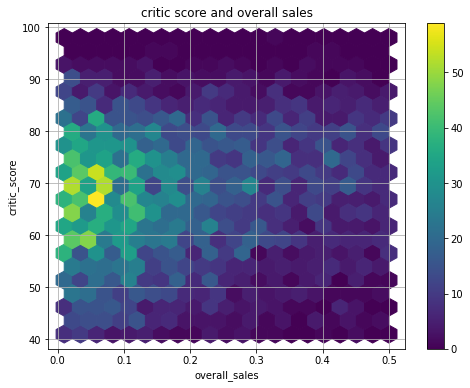

In [159]:
data[(data['critic_score'] > 40) & (data['overall_sales'] <= 0.5)].plot(kind='hexbin', x='overall_sales', y='critic_score', gridsize=20, figsize=(8, 6),
                          sharex=False, grid=True, reduce_C_function=np.mean, cmap="viridis",
              title='critic score and overall sales')
plt.show()

Из этой диаграммы видно, что в общем по платформам большинство игр получают оценки чуть лучше, чем игры с PS3, однако их продажи сдвинуты влево относительно предыдущей hexbin.

Резюмируя:

С увеличением оценки критиков увеличивается шанс игры на успешную продажу. Однако это может не быть следствием причинно-следственной связи. В целом, коррляция безусловно есть, но она несильная.

Платформа PS3 как раз хорошо это иллюстрирует. Несмотря на то, что большинство ее игр поучают оценку ниже, чем большинство игр со всех платформ, ее продажи при тех же оценках в среднем выше. 

<div class="alert-success"> 
<b>Комментарий ревьюера 👍 </b>

да, согласен, это необязательно должно быть причинно-следственная связь

Теперь обратимся к исследванию игр по жанрам.

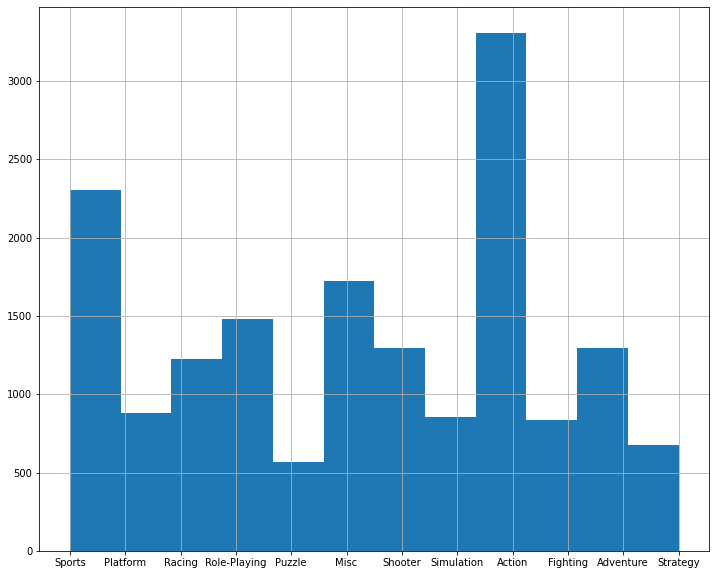

In [160]:
data['genre'].hist(bins=len(data['genre'].unique()), figsize=(12, 10))
plt.show();

Построим общую гистограмму. Сразу видно, что больше всего игр имеют жанр Action, второе место занимает Sports. Далее Misc и Role-playing.

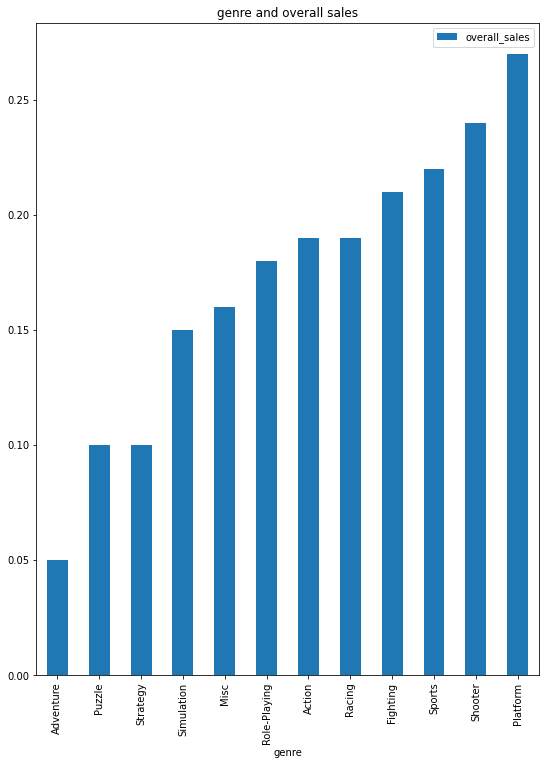

In [161]:
to_plot = data.groupby('genre').median()['overall_sales'].reset_index().sort_values(by='overall_sales')
to_plot.plot(kind='bar', x='genre', y='overall_sales', figsize=(9, 12), title='genre and overall sales')
plt.show()

Теперь посмотрим на продажи игр по жанрам. Здесь Action занимает уже далеко не первое место. Лидирующая позиция отводится жанру Platform. Вообще диаграмма полуается ступенчатой, нельзя точно определить границу между жанрами, которые продаются хорошо, и жанрами, которые продаются плохо.

In [162]:
def pies(values, param):
    colors = sns.color_palette('pastel')
    new_pivot = data.pivot_table(index=param, values=values, aggfunc=['sum'])
    new_pivot.columns = [values + '_sum']
    new_pivot[values + '_sum'] = new_pivot[values + '_sum'] / new_pivot[values + '_sum'].sum()
    print(new_pivot.sort_values(by=values + '_sum', ascending=False))
    new_pivot.plot(y=values + '_sum', kind='pie', colors = colors, figsize=(20,20), normalize=False)
    plt.show()

Создадим функцию, которая позволит визуализироать данные (уже не медиану, а долю от суммарных продаж) в виде круговой диаграммы.

              overall_sales_sum
genre                          
Action                 0.194741
Sports                 0.148584
Shooter                0.118143
Role-Playing           0.105632
Platform               0.093660
Misc                   0.089659
Racing                 0.082081
Fighting               0.050220
Simulation             0.044014
Puzzle                 0.027216
Adventure              0.026472
Strategy               0.019578


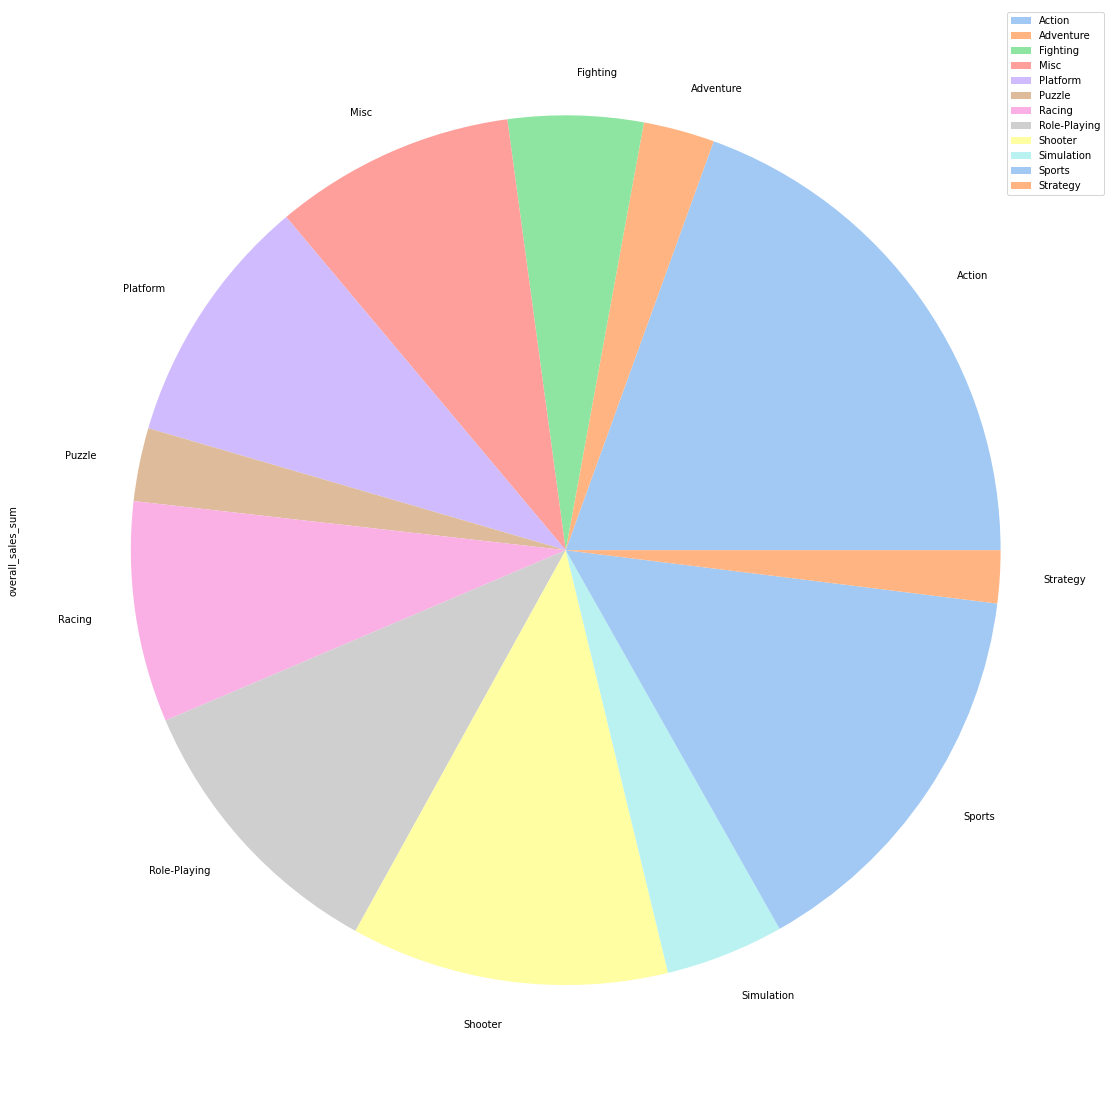

In [163]:
pies('overall_sales', 'genre')

Наглядно.

Доля от суммарных продаж и медианные значения для разных жанров в основном совпадают.

<div class="alert-success"> 
<b>Комментарий ревьюера 👍 </b>

Здорово, что ты посмотрела на медианные значения, а не только на общие продажи

Теперь перейдем к составлению портрета пользователя из каждого региона.

<div class="alert-warning"> 
<b>Комментарий ревьюера 💡</b> 

Нужно иметь какое-то оформление, заголовки и т.д., ибо сейчас это сложно воспринимается. Представь, что ты презентуешь это заказчику / бизнесу, сторонний читатель банально ничего не поймет, где переход от одного пункта к другому

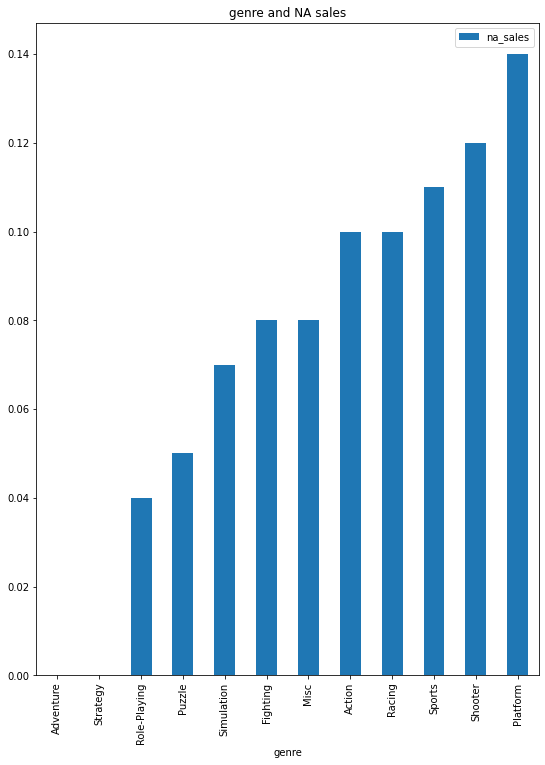

In [164]:
to_plot = data.groupby('genre').median()['na_sales'].reset_index().sort_values(by='na_sales')
to_plot.plot(kind='bar', x='genre', y='na_sales', figsize=(9, 12), title='genre and NA sales')
plt.show()

Теперь shooter продается лучше, чем sports, racing и action популярнее, чем в целом по миру. Самый популярный жанр все также - platform.

              na_sales_sum
genre                     
Action            0.198822
Sports            0.154604
Shooter           0.134709
Platform          0.102372
Misc              0.092037
Racing            0.082199
Role-Playing      0.076021
Fighting          0.050792
Simulation        0.041553
Puzzle            0.027901
Adventure         0.023384
Strategy          0.015605


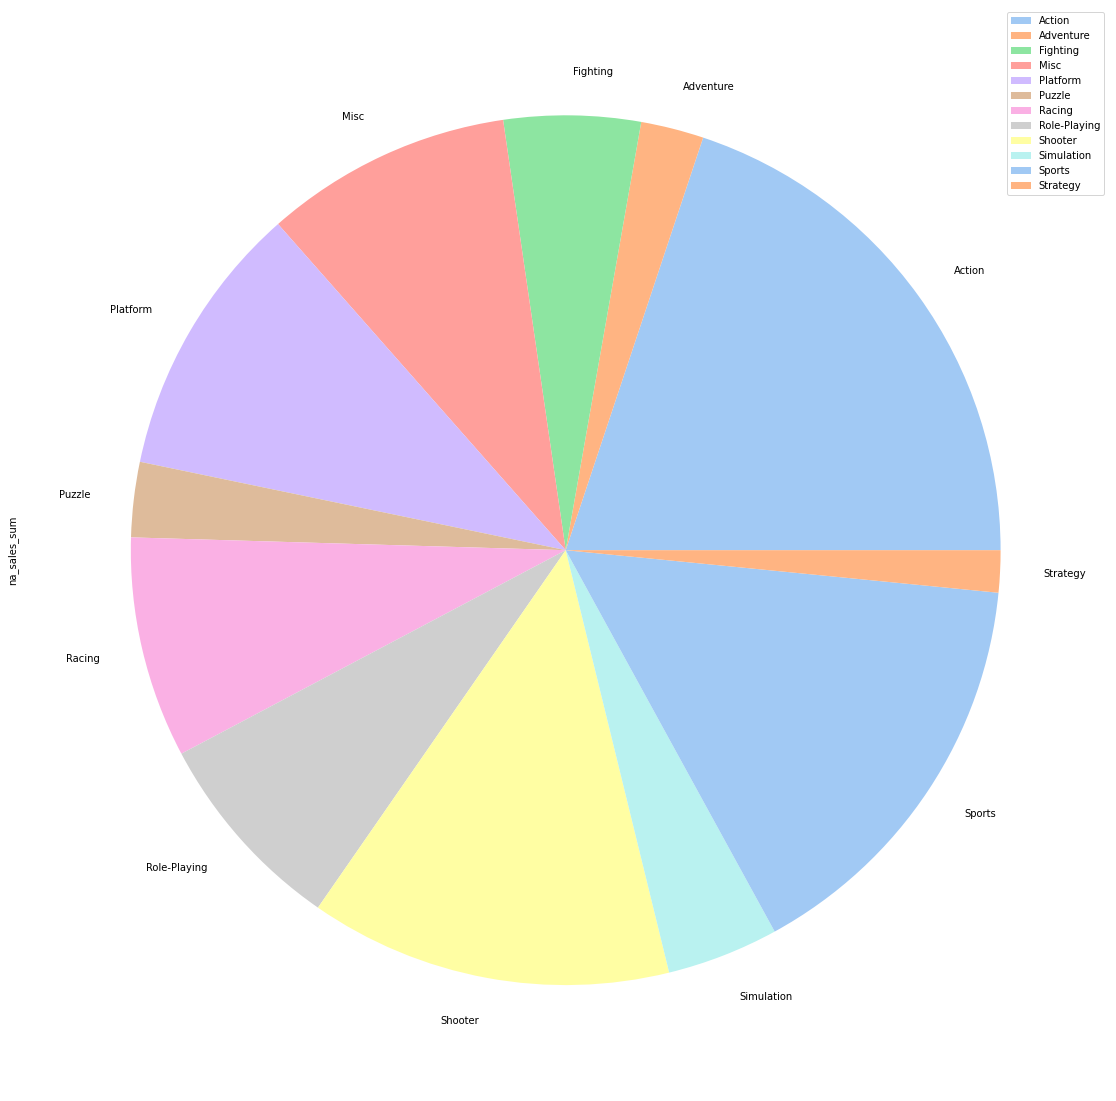

In [165]:
pies('na_sales', 'genre')

Общая доля продаж у Sports в NA все же больше, чем у Shooter: таких игр просто больше. Role-playing заметно менее популярен, чем на общей диаграмме: видимо, эту игру предпочитают в каком-то другом регионе.

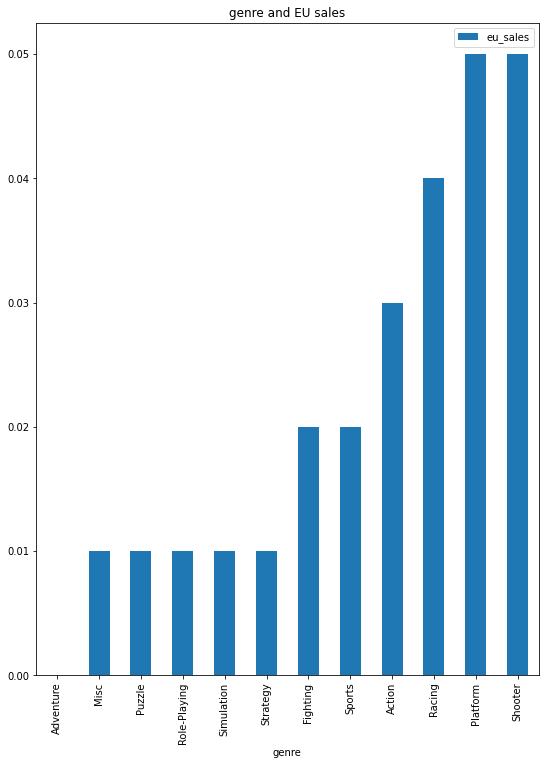

In [166]:
to_plot = data.groupby('genre').median()['eu_sales'].reset_index().sort_values(by='eu_sales')
to_plot.plot(kind='bar', x='genre', y='eu_sales', figsize=(9, 12), title='genre and EU sales')
plt.show()

Platform сдало лидирующую позицию, но продается очень эффективно. Лучше всего в EU продается Shooter. Racing и Action здесь тоже обычно не подводят ожиданий.

              eu_sales_sum
genre                     
Action            0.212941
Sports            0.154741
Shooter           0.131067
Racing            0.097717
Misc              0.087762
Platform          0.083090
Role-Playing      0.078444
Simulation        0.047235
Fighting          0.041256
Adventure         0.026337
Puzzle            0.020744
Strategy          0.018665


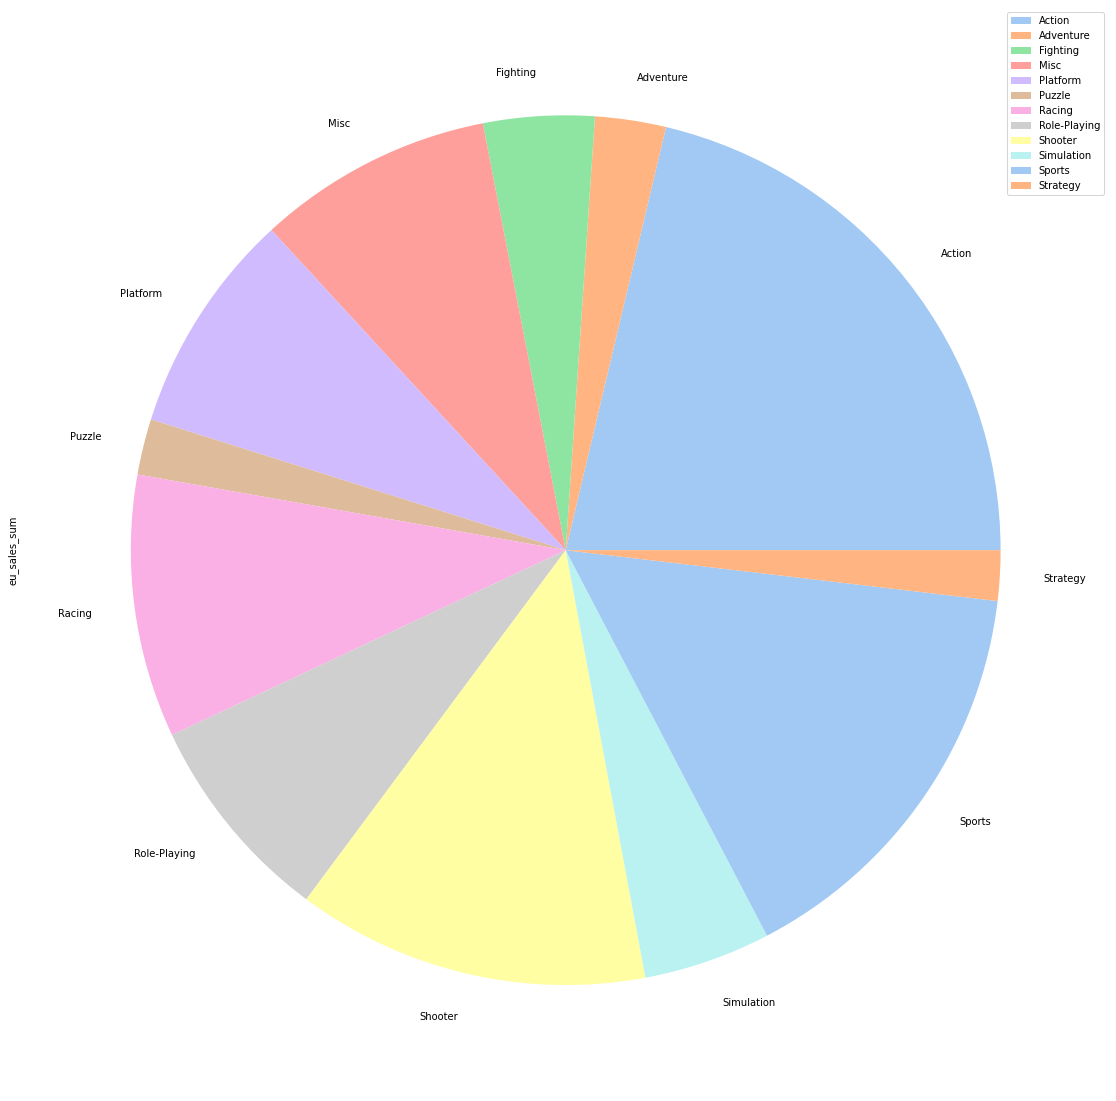

In [167]:
pies('eu_sales', 'genre')

По долям от суммарных продаж совсем другая картина. Больше всего продаются Action и Sports, Shooter занимает только третье место, а Platform и вовсе шестое.

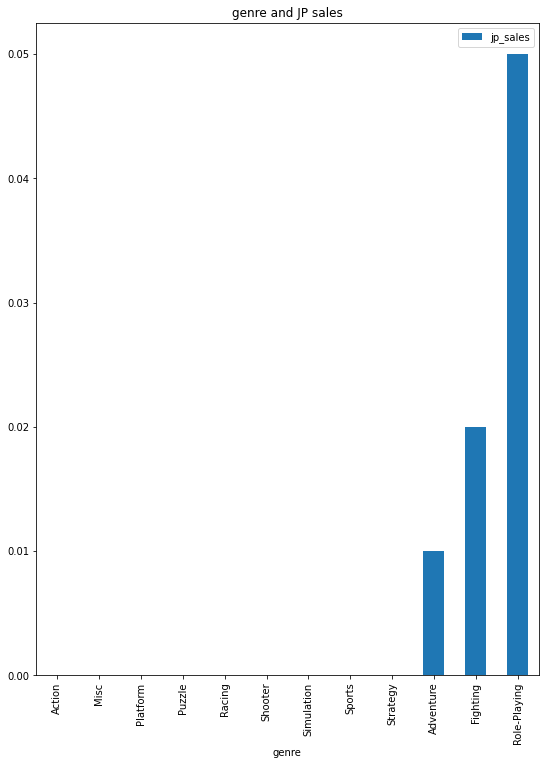

In [168]:
to_plot = data.groupby('genre').median()['jp_sales'].reset_index().sort_values(by='jp_sales')
to_plot.plot(kind='bar', x='genre', y='jp_sales', figsize=(9, 12), title='genre and JP sales')
plt.show()

В JP ни Action, ни Sports никому не нужны, ведь это тот самый регион, за счет которого игры в жанре Role-playing являются такими популярными.

              jp_sales_sum
genre                     
Role-Playing      0.273810
Action            0.124078
Sports            0.104545
Platform          0.101275
Misc              0.082920
Fighting          0.067625
Simulation        0.049309
Puzzle            0.043916
Racing            0.043877
Adventure         0.040476
Strategy          0.038198
Shooter           0.029970


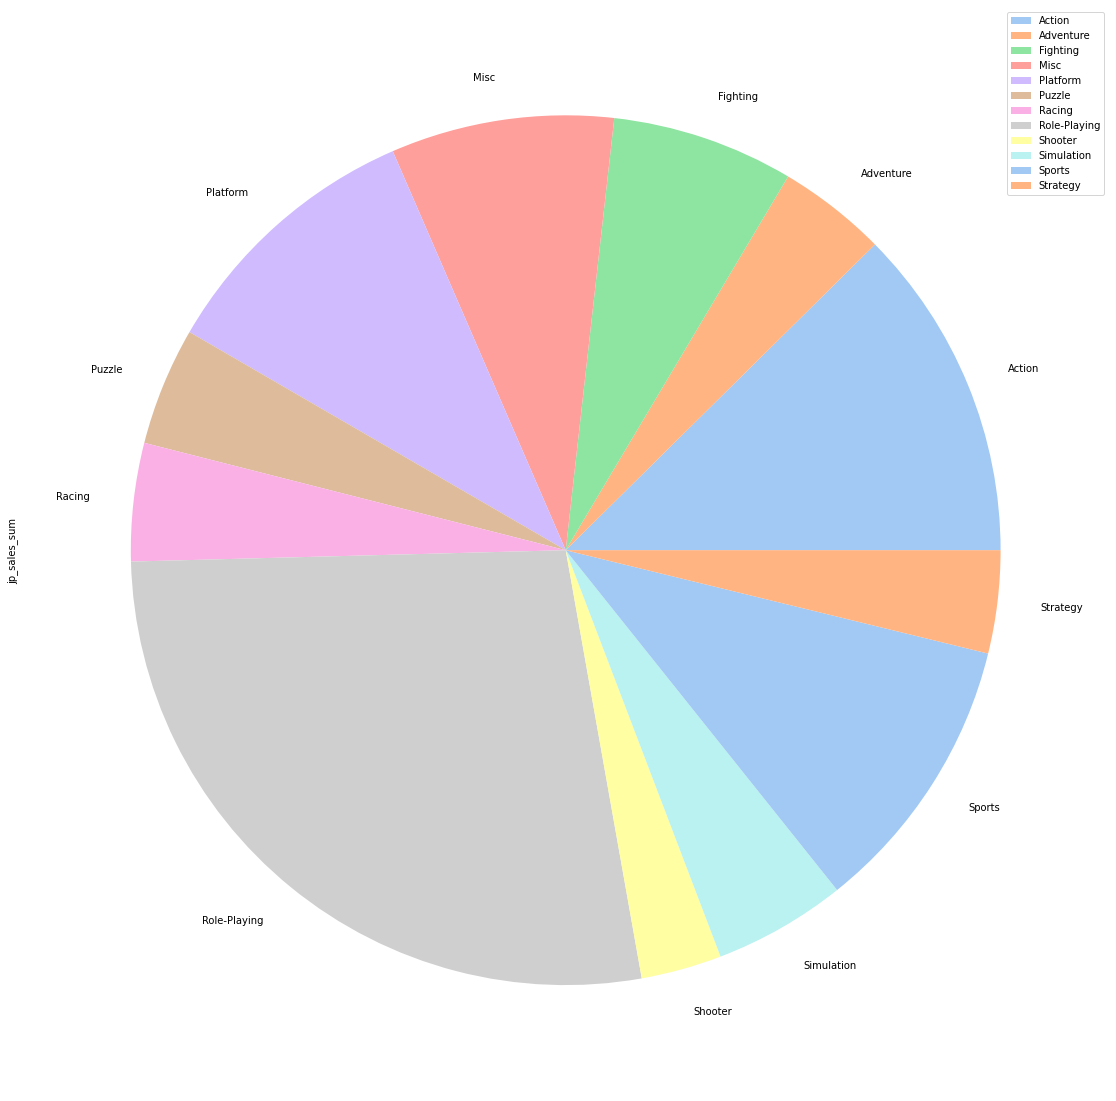

In [169]:
pies('jp_sales', 'genre')

Несмотря на информацию выше, Action, Sports и Platform здесь продают весьма активно, несмотря на то, что Fighting и Adventure здесь явно более популярны. Предпочтение пользователей к Role-playing в продажах учтено. 

Теперь будем исследвать предпочтения пользователей из разных регионов по платформам.

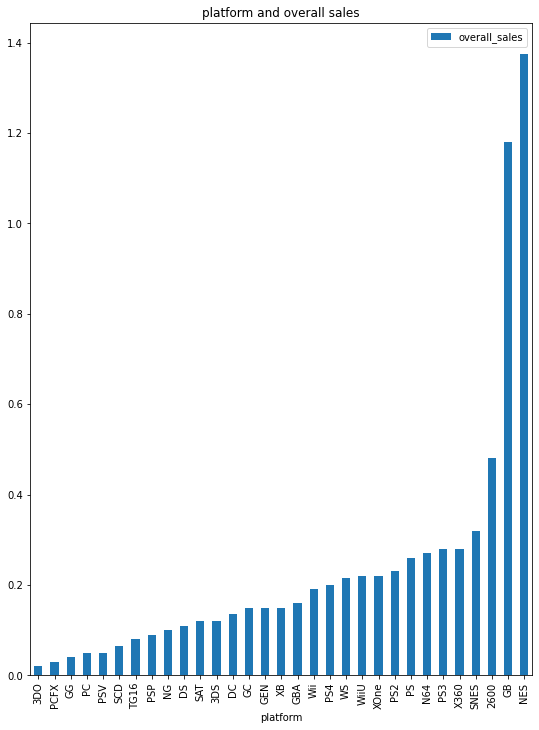

In [170]:
to_plot = data.groupby('platform').median()['overall_sales'].reset_index().sort_values(by='overall_sales')
to_plot.plot(kind='bar', x='platform', y='overall_sales', figsize=(9, 12), title='platform and overall sales')
plt.show()

NES и GB в целом были очень эффективными платформами.

          overall_sales_sum
platform                   
PS2                0.139949
X360               0.109054
PS3                0.105662
Wii                0.101105
DS                 0.091076
PS                 0.082545
PS4                0.035640
GBA                0.035497
PSP                0.032847
3DS                0.029249
PC                 0.029016
GB                 0.028865
XB                 0.028541
NES                0.028482
N64                0.024733
SNES               0.022695
GC                 0.022319
XOne               0.018075
2600               0.009811
WiiU               0.009325
PSV                0.006105
SAT                0.003811
GEN                0.003216
DC                 0.001810
SCD                0.000211
NG                 0.000163
WS                 0.000161
TG16               0.000018
3DO                0.000011
GG                 0.000005
PCFX               0.000003


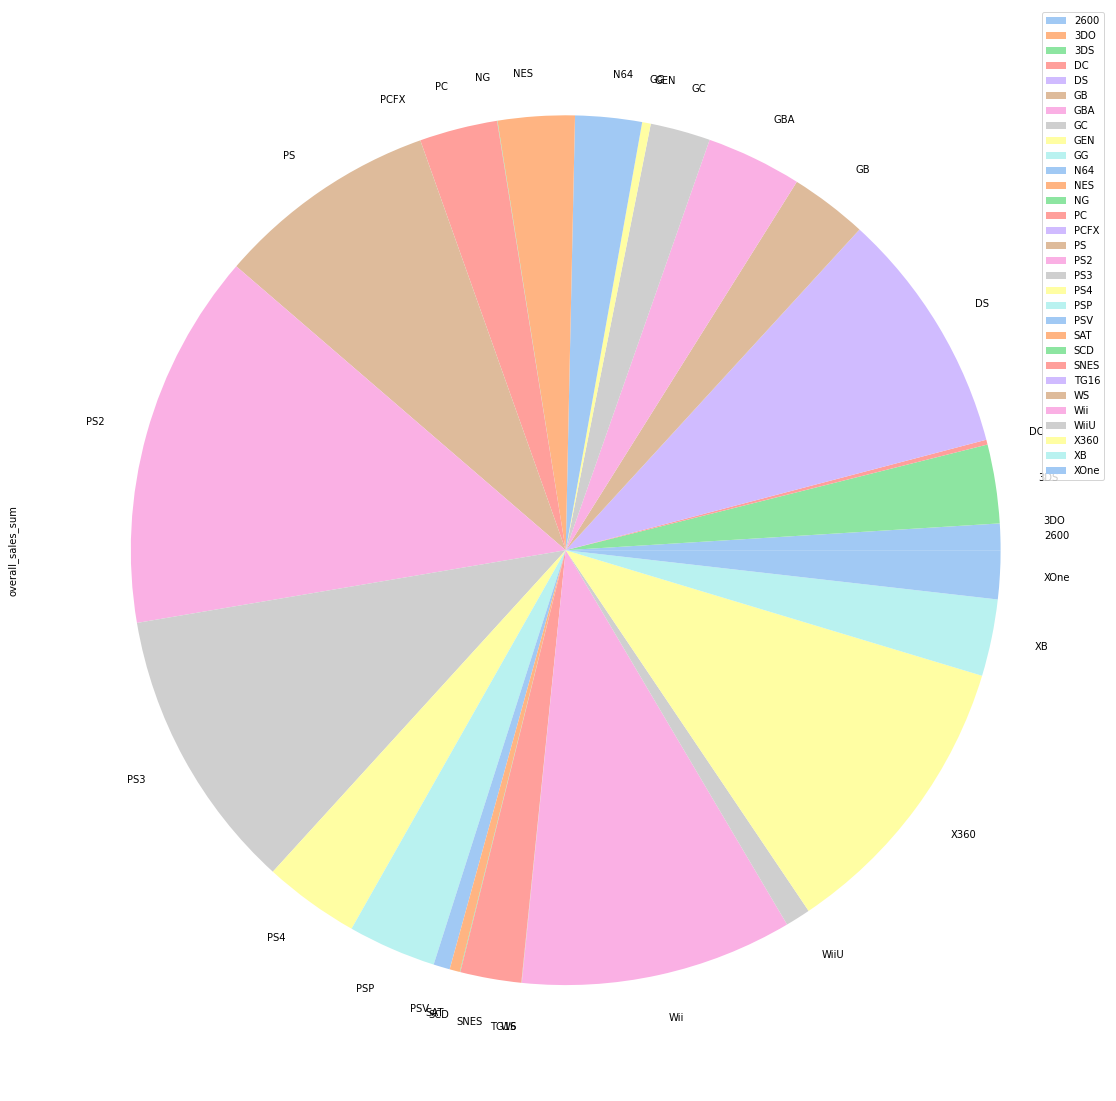

In [171]:
pies('overall_sales', 'platform')

Наиболее активной, однако, была платформа PS2.

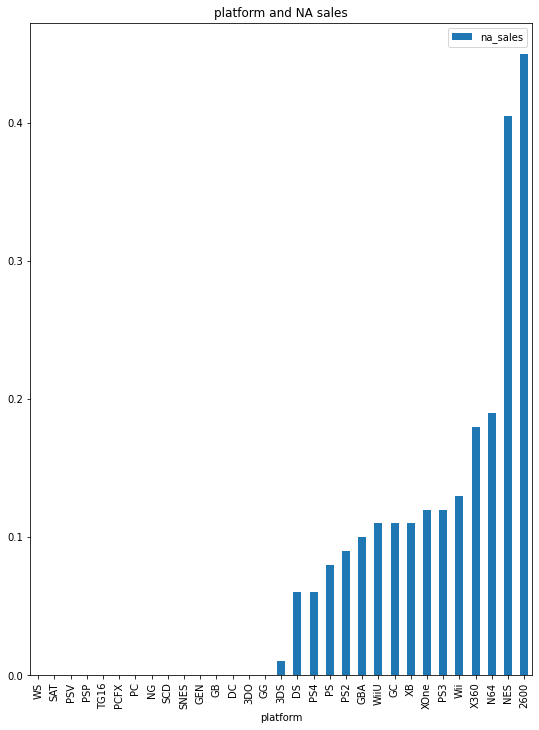

In [172]:
to_plot = data.groupby('platform').median()['na_sales'].reset_index().sort_values(by='na_sales')
to_plot.plot(kind='bar', x='platform', y='na_sales', figsize=(9, 12), title='platform and NA sales')
plt.show()

В NA дела шли лучше всего у 2600 и NS. GB здесь явно сдает позиции. PS3 держится на стабильном уровне, как и Wii, и WiiU.

          na_sales_sum
platform              
X360          0.137222
PS2           0.131966
Wii           0.112145
PS3           0.089862
DS            0.087600
PS            0.077099
GBA           0.042410
XB            0.041936
N64           0.031996
GC            0.030391
NES           0.029009
GB            0.026176
PS4           0.025047
PSP           0.024709
PC            0.021500
XOne          0.021449
3DS           0.019038
2600          0.018607
SNES          0.014104
WiiU          0.008776
GEN           0.004439
PSV           0.002872
DC            0.001251
SCD           0.000230
SAT           0.000166
3DO           0.000000
PCFX          0.000000
NG            0.000000
GG            0.000000
TG16          0.000000
WS            0.000000


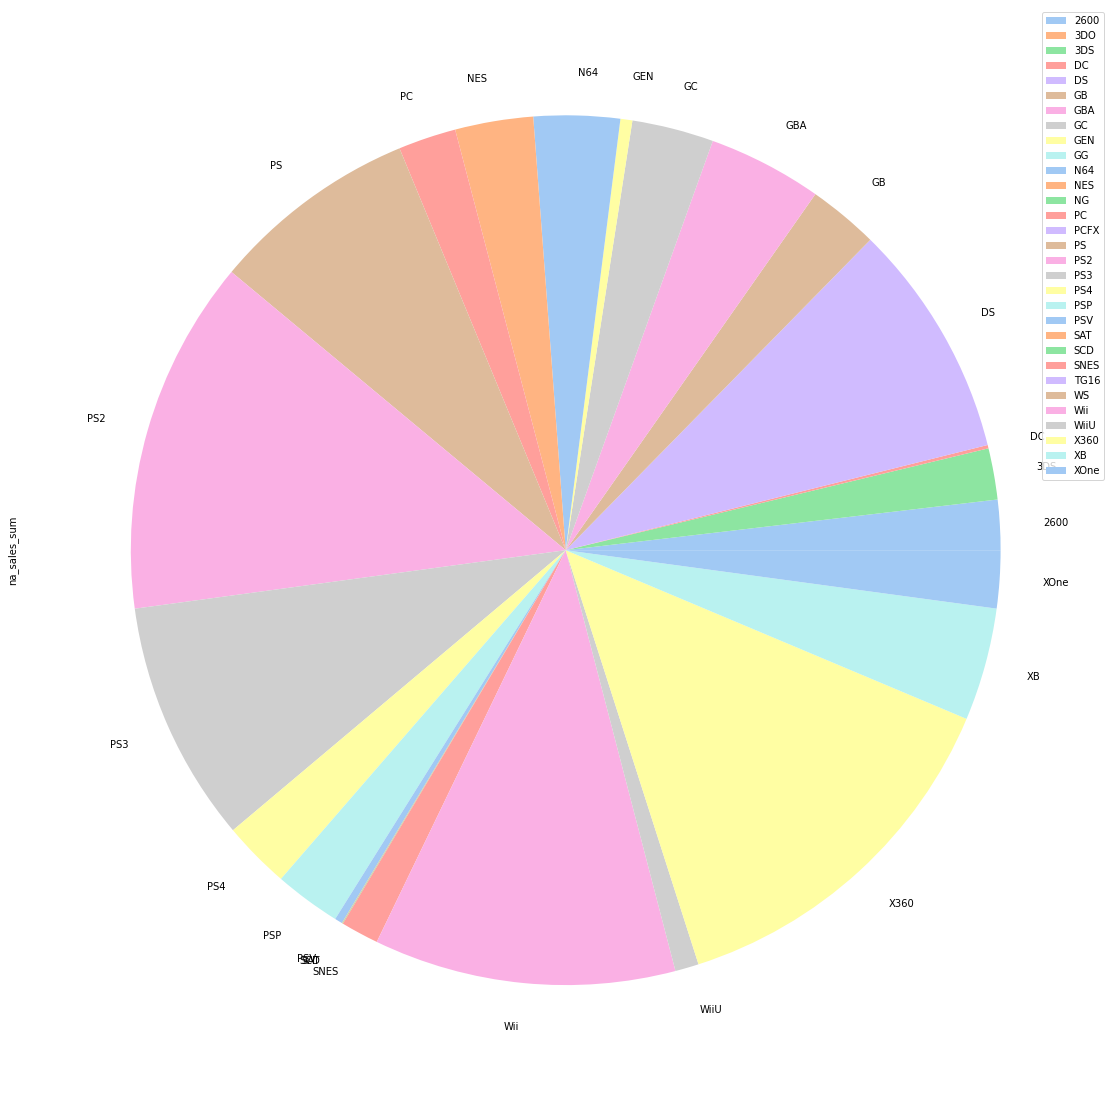

In [173]:
pies('na_sales', 'platform')

X360, PS2 и Wii были здесь самыми активными.

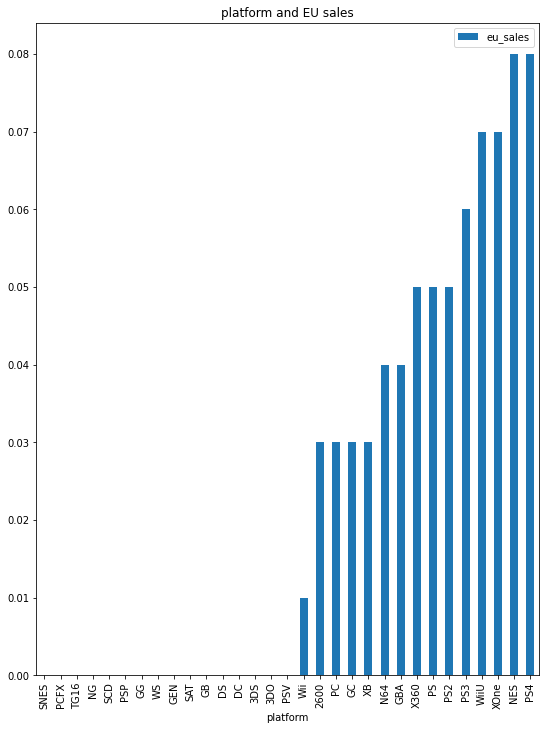

In [174]:
to_plot = data.groupby('platform').median()['eu_sales'].reset_index().sort_values(by='eu_sales')
to_plot.plot(kind='bar', x='platform', y='eu_sales', figsize=(9, 12), title='platform and EU sales')
plt.show()

NES и PS4 наиболее успешно вели продажи в EU. Стоит также отметить XOne, WiiU и PS3.

          eu_sales_sum
platform              
PS2           0.138614
PS3           0.136356
X360          0.111815
Wii           0.107648
PS            0.088508
DS            0.078515
PS4           0.058795
PC            0.058495
GBA           0.031083
PSP           0.027345
3DS           0.025533
XB            0.024857
XOne          0.021499
GB            0.019798
N64           0.017098
GC            0.015969
WiiU          0.010472
NES           0.008814
SNES          0.007934
PSV           0.005447
GEN           0.002300
2600          0.002025
DC            0.000704
SAT           0.000225
SCD           0.000150
WS            0.000000
TG16          0.000000
PCFX          0.000000
GG            0.000000
3DO           0.000000
NG            0.000000


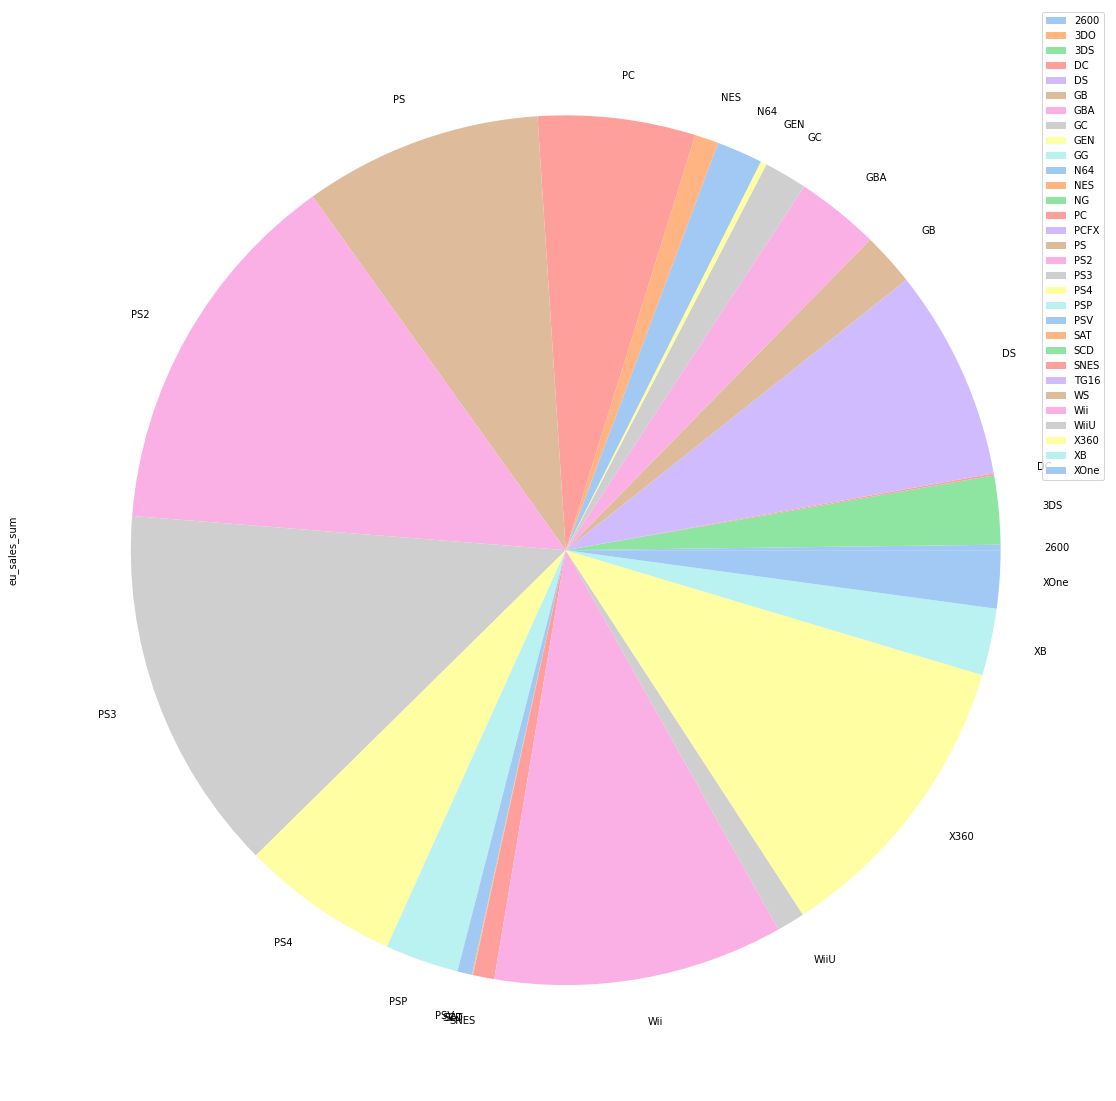

In [175]:
pies('eu_sales', 'platform')

PS2, PS3, XOne и Wii совершили больше всего продаж в этом регионе.

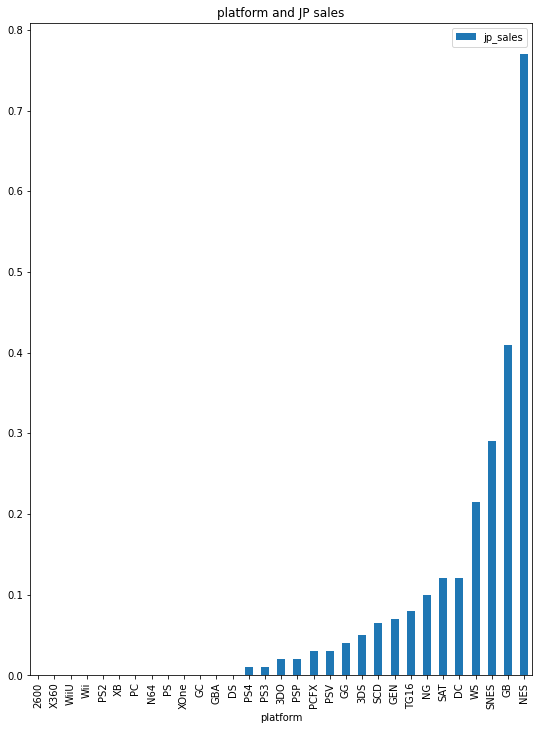

In [176]:
to_plot = data.groupby('platform').median()['jp_sales'].reset_index().sort_values(by='jp_sales')
to_plot.plot(kind='bar', x='platform', y='jp_sales', figsize=(9, 12), title='platform and JP sales')
plt.show()

В JP NES самая успешная платформа. Возможно, это связано с предпочитанием Role-playing.

          jp_sales_sum
platform              
DS            0.135607
PS            0.108303
PS2           0.106567
SNES          0.090304
3DS           0.077961
NES           0.076435
GB            0.065952
PS3           0.061528
PSP           0.058793
Wii           0.052904
GBA           0.036075
N64           0.026158
SAT           0.024995
PSV           0.016922
GC            0.016534
PS4           0.012366
WiiU          0.010080
X360          0.009530
DC            0.006632
GEN           0.002069
NG            0.001116
WS            0.001100
XB            0.001069
SCD           0.000349
XOne          0.000263
PC            0.000132
TG16          0.000124
3DO           0.000077
GG            0.000031
PCFX          0.000023
2600          0.000000


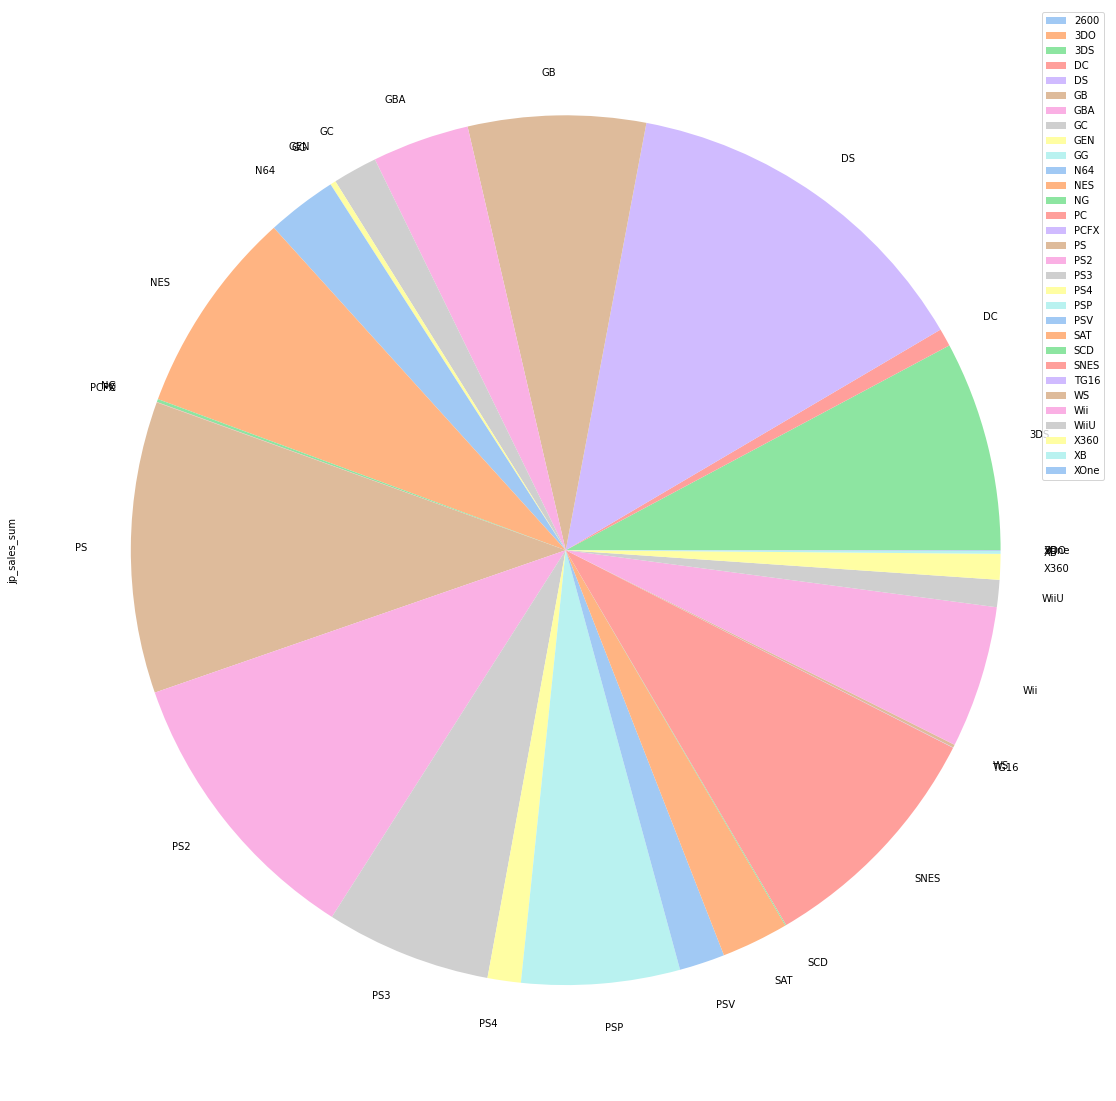

In [177]:
pies('jp_sales', 'platform')

<div class="alert-success"> 
<b>Комментарий ревьюера 👍 </b>

Графики - супер!

Самыми активными платформами, однако, являются DS, PS, PS2. Action и Sports здесь ведь действительно продают весьма активно, несмотря на то, что они не очень популярны у пользователей из этого региона.

Теперь посмотрим, влияет ли рейтинг на продажи в разных регионах.

In [178]:
print(data['rating'].unique())

['E' 'No rating' 'M' 'T' 'E10+' 'K-A' 'AO' 'EC' 'RP']


Сперва определимся со значениями аббревиатур. E - everyone, M - mature, T - teen, E10+ - от 10, K-A - kids-adults (6+), AO - adults only, EC - early childhood, RP - rating pending.

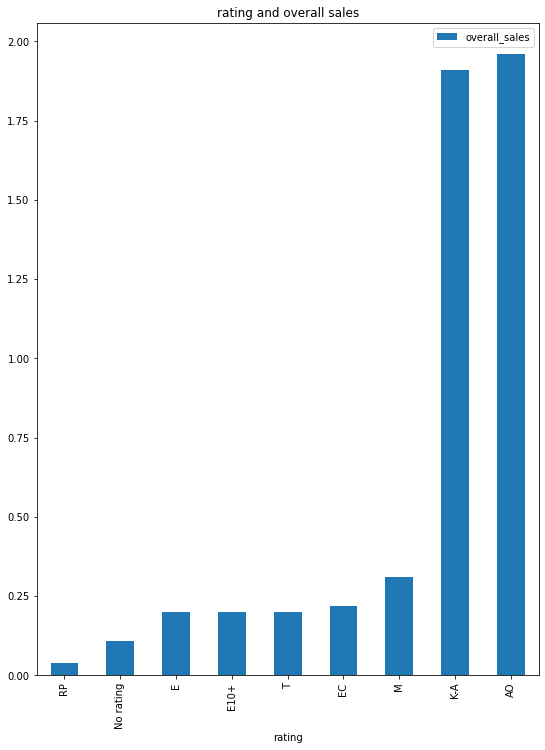

In [179]:
to_plot = data.groupby('rating').median()['overall_sales'].reset_index().sort_values(by='overall_sales')
to_plot.plot(kind='bar', x='rating', y='overall_sales', figsize=(9, 12), title='rating and overall sales')
plt.show()

Kids-adults и adults only - наиболее успешно продаваемые категории игр в мире.

           overall_sales_sum
rating                      
No rating           0.320170
E                   0.273146
T                   0.167123
M                   0.165926
E10+                0.072720
K-A                 0.000490
AO                  0.000222
EC                  0.000199
RP                  0.000005


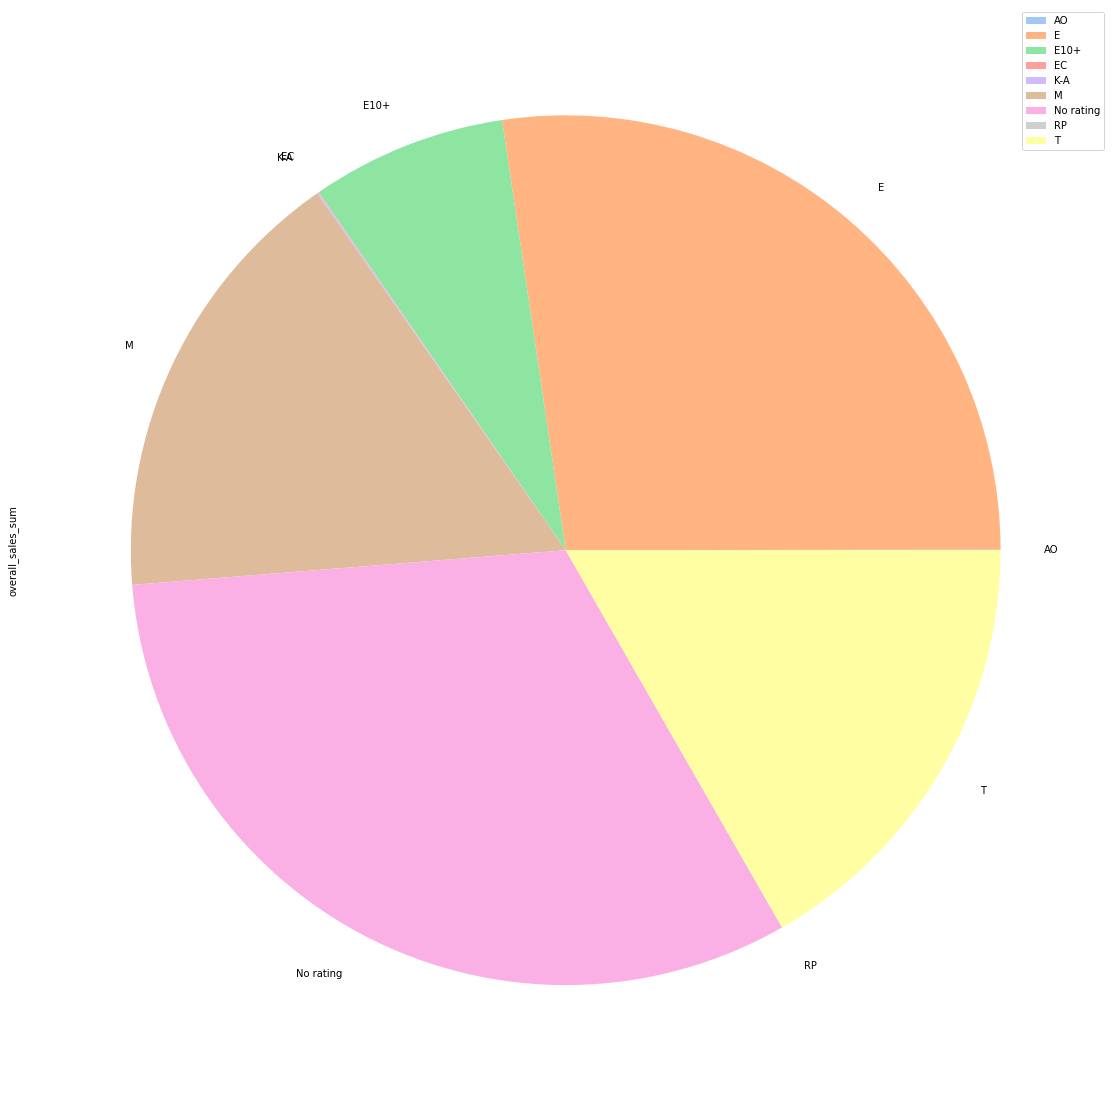

In [180]:
pies('overall_sales', 'rating')

Наиболее активно продаются, однако, игры без присвоенного рейтинга и категория everyone.

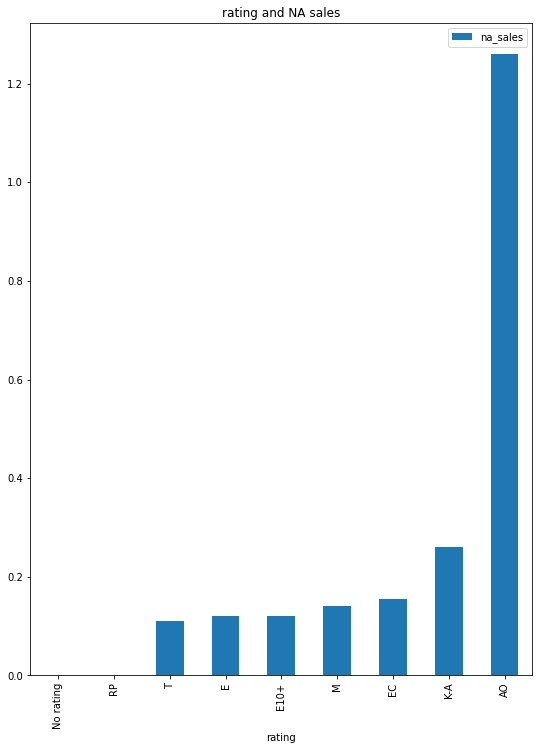

In [181]:
to_plot = data.groupby('rating').median()['na_sales'].reset_index().sort_values(by='na_sales')
to_plot.plot(kind='bar', x='rating', y='na_sales', figsize=(9, 12), title='rating and NA sales')
plt.show()

в NA adults only продается намного успешнее остальных категорий.

           na_sales_sum
rating                 
E              0.293508
No rating      0.282359
T              0.172202
M              0.171117
E10+           0.079582
K-A            0.000590
EC             0.000352
AO             0.000290
RP             0.000000


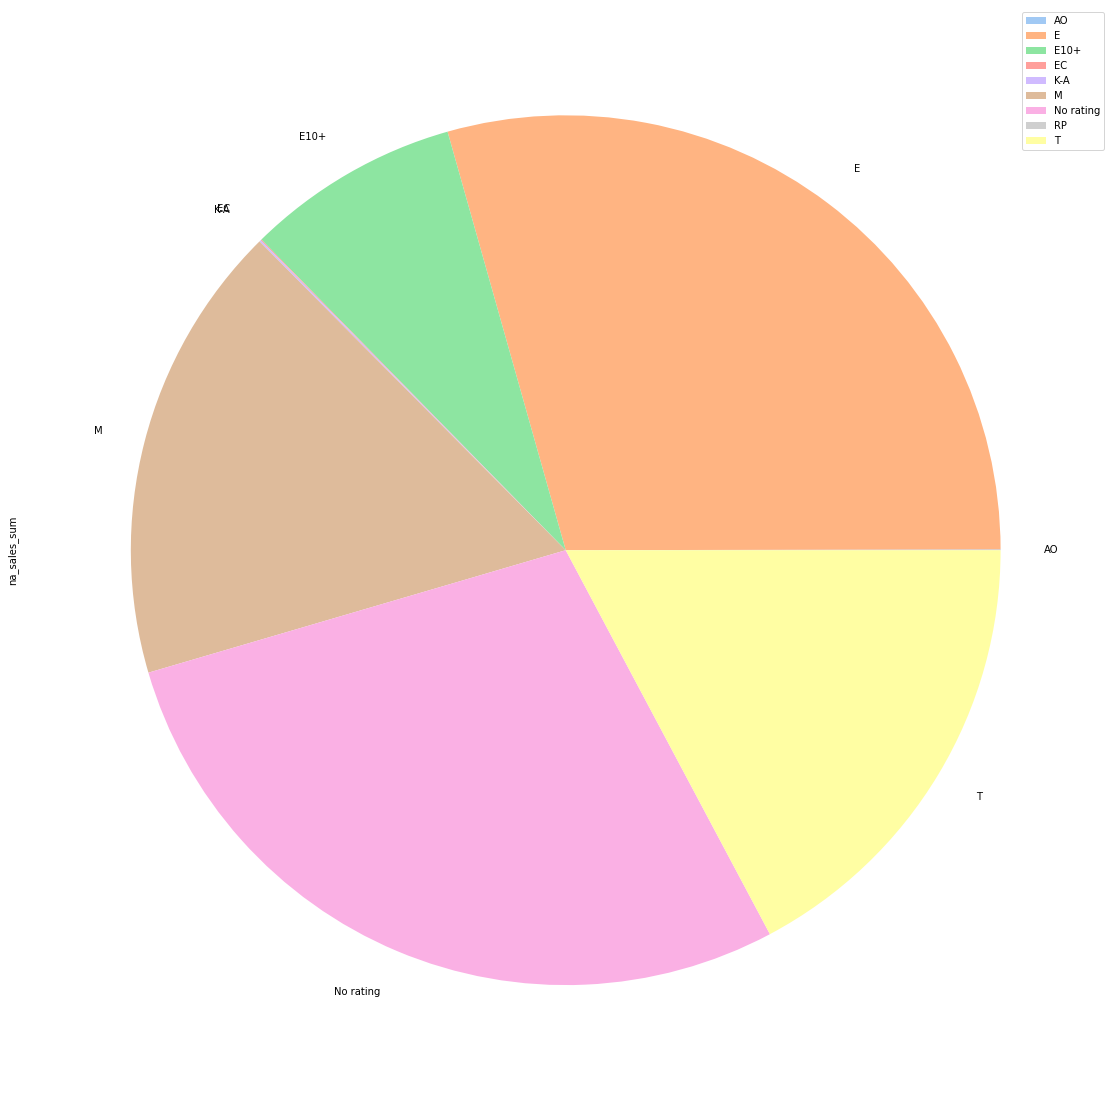

In [182]:
pies('na_sales', 'rating')

Продается adults only едва ли, зато игры категории everyone представлены масштабно.

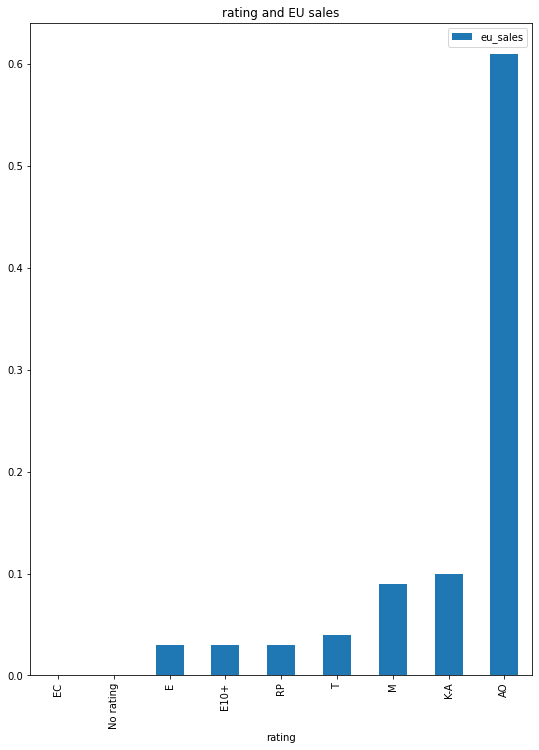

In [183]:
to_plot = data.groupby('rating').median()['eu_sales'].reset_index().sort_values(by='eu_sales')
to_plot.plot(kind='bar', x='rating', y='eu_sales', figsize=(9, 12), title='rating and EU sales')
plt.show()

Аналогично в EU.

           eu_sales_sum
rating                 
E              0.293318
No rating      0.254055
M              0.200027
T              0.175769
E10+           0.076406
AO             0.000254
K-A            0.000113
EC             0.000046
RP             0.000013


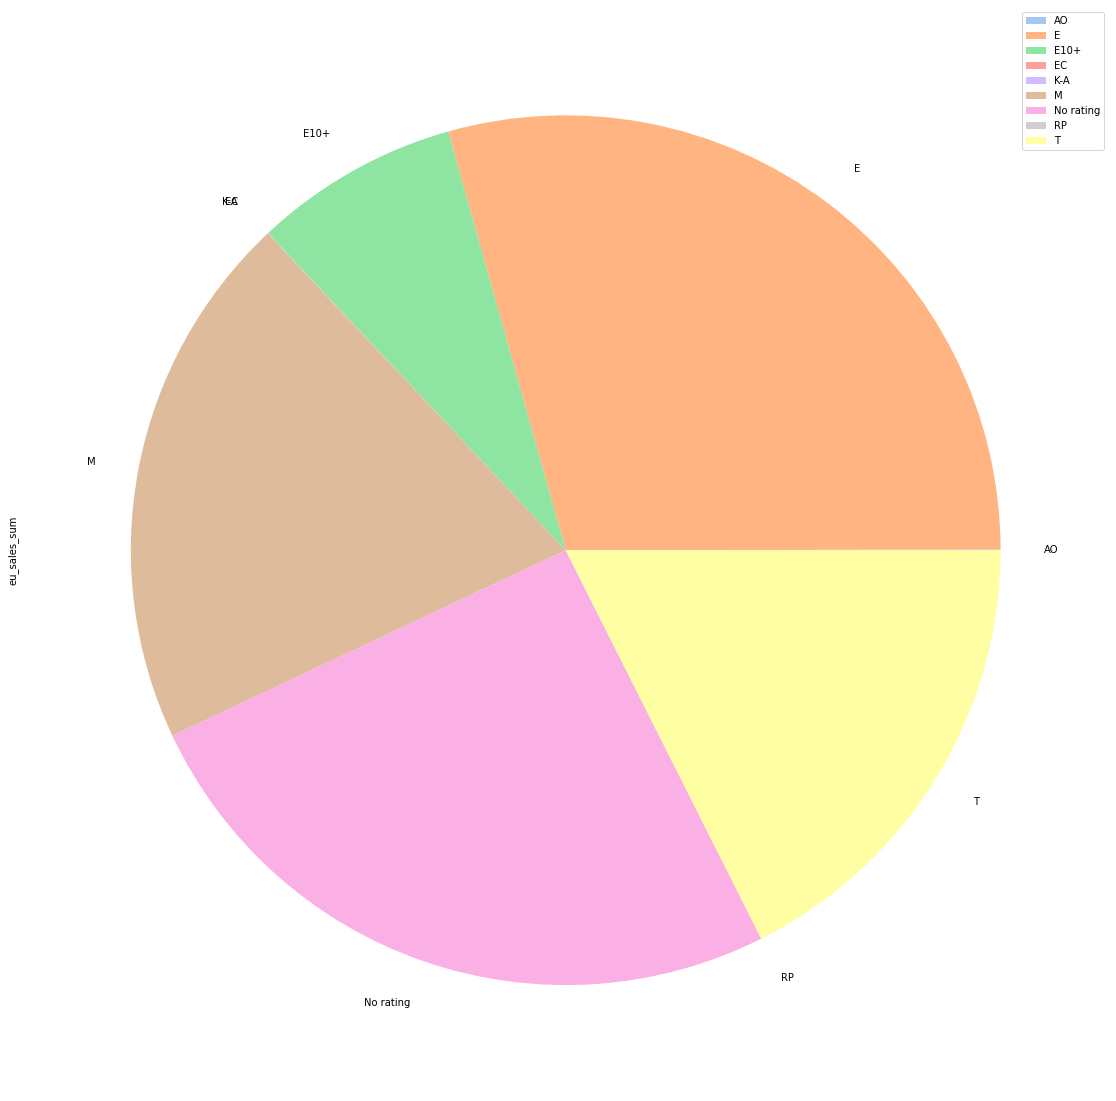

In [184]:
pies('eu_sales', 'rating')

Ситуация в целом аналогична NA.

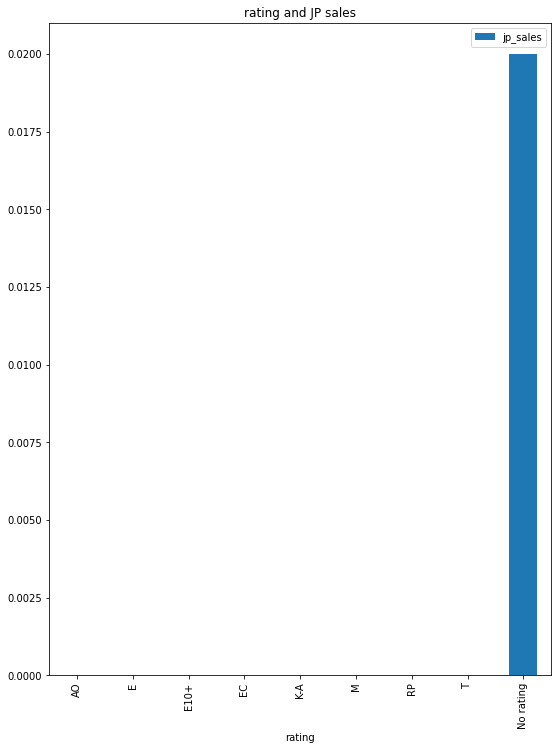

In [185]:
to_plot = data.groupby('rating').median()['jp_sales'].reset_index().sort_values(by='jp_sales')
to_plot.plot(kind='bar', x='rating', y='jp_sales', figsize=(9, 12), title='rating and JP sales')
plt.show()

Остальные категории не идут ни в какое сравнение с успешностью продаж игр без рейтинга!

           jp_sales_sum
rating                 
No rating      0.648314
E              0.153381
T              0.116764
M              0.049262
E10+           0.031147
K-A            0.001131
AO             0.000000
EC             0.000000
RP             0.000000


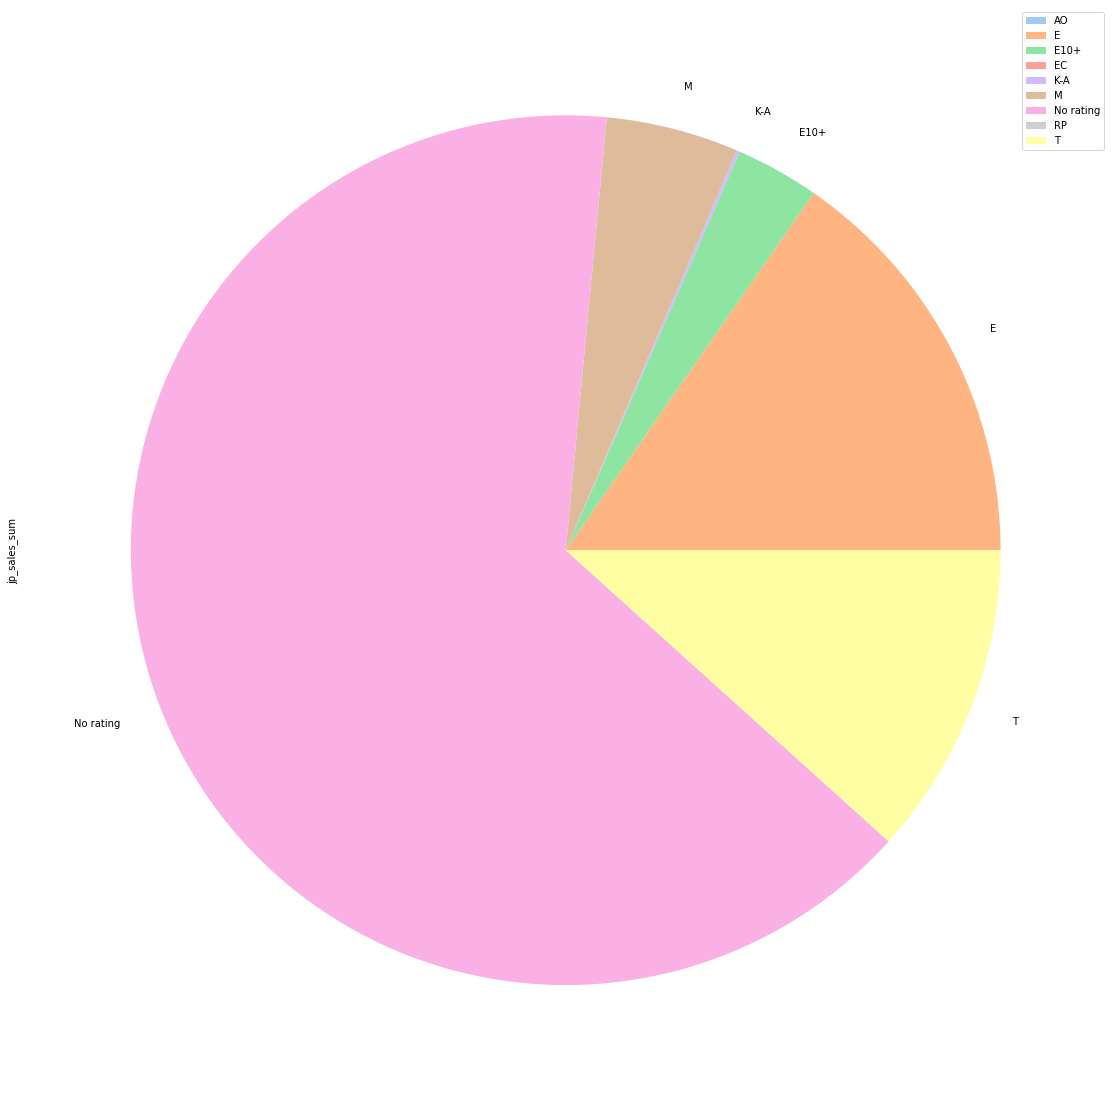

In [186]:
pies('jp_sales', 'rating')

<div class="alert-success"> 
<b>Комментарий ревьюера 👍 </b>
    
Иногда пропуск сам по себе является ценной информацией. Например, нужно держать в уме, для каких стран создавалась система ESRB? Будут ли стараться авторы игр для локального рынка других стран получить рейтинг ESRB? Поэтому очень здорово, что у тебя в графиках есть значения с пропусками

В JP и продают такие игры наиболее активно.

Таким образом, предпочтения пользователей в разных регионах очень важно учитывать для правильного планирования рекламных компаний. Как видим, далеко не всегда широко представлено именно то, что требуется.

Перейдем к проверке статистических гипотез.

Проверим, одинаковы ли средние пользовательские рейтинги платформ Xbox One и PC.

H0: Cредние пользовательские рейтинги платформ Xbox One и PC равны.

H1: Cредние пользовательские рейтинги платформ Xbox One и PC существенно различаются.

In [187]:
xone_user_ratings = data.loc[data['platform'] == 'XOne', 'user_score']
pc_user_ratings = data.loc[data['platform'] == 'PC', 'user_score']
results = st.ttest_ind(xone_user_ratings, pc_user_ratings, equal_var = True)
alpha = 0.5
print(results.pvalue)
if results.pvalue < alpha:
    print('Отвергаем гипотезу H0')
else:
    print('Нет оснований отвергнуть гипотезу')

0.0007068097266608117
Отвергаем гипотезу H0


Многое зависит от правильного выбора платформы. Cредние пользовательские рейтинги платформ Xbox One и PC существенно различаются.

Теперь проверим, разные ли средние пользовательские рейтинги жанров Action и Sports.

H0: Cредние пользовательские рейтинги жанров Action и Sports однаковые.

H1: Cредние пользовательские рейтинги жанров Action и Sports разные.

In [188]:
action_user_ratings = data.loc[data['genre'] == 'Action', 'user_score']
sports_user_ratings = data.loc[data['genre'] == 'Sports', 'user_score']
results = st.ttest_ind(action_user_ratings, sports_user_ratings, equal_var = True)
alpha = 0.5
print(results.pvalue)
if results.pvalue < alpha:
    print('Отвергаем гипотезу H0')
else:
    print('Нет оснований отвергнуть гипотезу')

7.492568776804889e-09
Отвергаем гипотезу H0


Многое зависит от правильного выбора жанра. Cредние пользовательские рейтинги жанров Action и Sports разные.

Статистический критерий

Для проверки статистических гипотез использовалась функция st.ttest_ind(), так как в контексте данной задачи мы выясняли, равны ли средние двух различных, независимых друг от друга выборок. Мы вычисляли p-value и затем сравнивали его с заданным статистическим уровнем значимости. Так как в обоих случаях p-value оказалось меньше уровня значимости (0.05), мы отвергли обе гипотезы.

<div class="alert-danger"> 
<b>Комментарий ревьюера ❌</b> 

Ничего не сказано про выбранный статистический критерий; нужно еще иметь пояснение, почему используется именно он

ОБЩИЙ ВЫВОД

В процессе исследования была обработана информация более чем о 16 тысячах игр, для каждой из которых было указано 10 параметров. Были устранены неточности и пропуски, изменены типы данных там, где это необходимо.

Далее данные были проанализированы и визуализированы с целью выяснения взаимосвязи между различными параметрами и успешностью продукта. Были проверены статистические гипотезы. По результатам исследования можно утверждать, что:

1) Распределение продаж компьютерных игр по годам сильно разнится. Пик продаж пришелся на 2008. Сейчас их количество имеет тенденцию к уменьшению. Продажи не за все годы стоит учитывать для составления прогноза, так как за некоторые годы данные просто отсутствовали, что могло вносить неточности в анализ.

2) Продажи существенно изменяются по платформам. Существует характерный срок, в течение которого обычно существуют платформы - около 9 лет. На сегодня наиболее активными остаются 3DS, PC, PS3, PS4, PSV, Wii, WiiU, X360, XOne. За последний год из них объемы продаж выросли только у PS3 и Wii. Не изменились объемы продаж у PSV и WiiU. Объемы продаж 3DS и PC остаются стабильными уже на протяжении нескольких лет. Самой положительной динамика продаж была у PS3.

3) Отзывы пользователей и критиков не сильно, но положительно коррелируют с успешностью продаж игр. При чем корреляция прослеживается лучше в отношении отзывов критиков. С повышением оценок увеличивается шанс игры на то, чтобы стать популярной.

4) Больше всего игр имеют жанр Action, второе место занимает Sports. Далее Misc и Role-playing. Наибольший спрос, однако, наблюдается на Platform, Shooter, Sports. Нельзя точно определить границу между жанрами, которые продаются хорошо, и жанрами, которые продаются плохо.

5) Между пользователями из разных регионов существуют существенные различия в предпочтениях по жанрам и платформам. 

6) Рейтинг ESRB влияет на продажи в отдельном регионе.

7) Многое зависит от правильного выбора платформы. Cредние пользовательские рейтинги платформ Xbox One и PC существенно различаются.

8) Многое зависит от правильного выбора жанра. Cредние пользовательские рейтинги жанров Action и Sports разные.

РЕКОМЕНДАЦИИ

1) Наиболее выгодно инвестировать будет в платформы PS3, Wii, WiiU.

2) В условиях существующего рынка наиболее грамотно будет инвестировать в игры жанров Platform, Shooter, Sports. 

3) Предпочтения пользователей в разных регионах очень важно учитывать для правильного планирования рекламных компаний. Так, в NA предпочитают жанр Platform, 

<div class="alert-warning"> 
<b>Комментарий ревьюера 💡</b> 
    
Хорошшй общий вывод, но опять каждая строчка в отдельной ячейке :(

<div class="alert-danger"> 
<b>Комментарий ревьюера ❌</b> 
    
Отличный проект, тобою проделана большая работа, ты молодец!

Сперва похвалю за наличие везде промежуточных выводов, комментариев и рассуждений. Хорошая подготовка и предобработка данных. По коду тоже в целом все хорошо, в т.ч. и отличные графики и визуализация данных (но в идеале - можно еще и подписывать их). Безошибочный пункт портрета пользователей. Почти все отлично в проверке гипотез и исследовательском анализе
    
Что стоит доработать: сказать, какой статистический критерий для проверки гипотез был выбран и почему именно он; добавить other sales в столбец; выбрать актуальный срок для прогнозирования и сказать про жизненный цикл жизни платформы

Также я оставил несколько желтых комментариев. Думаю, и они будут тебе полезны.
    
Буду ждать доработок :) Удачи!

<div class="alert-success"> 
<b>Комментарий ревьюера 👍 Вторая итерация </b>

Проект стал еще лучше, принимаю. Успехов в дальнейшей учебе!